# Cell 1 — Installation and imports

In [ ]:
!pip install -q catboost shap

import os, json, time, glob, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import sklearn, xgboost, lightgbm, catboost

from joblib import Parallel, delayed
from IPython.display import display
from sklearn.datasets import load_wine, load_breast_cancer, fetch_openml
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_val_score)
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             average_precision_score)
from sklearn.preprocessing import label_binarize
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from scipy.stats import friedmanchisquare, wilcoxon, rankdata

warnings.filterwarnings("ignore")

print("CPU cores available:", os.cpu_count())
for name, module in [("numpy", np), ("pandas", pd), ("scikit-learn", sklearn),
                     ("xgboost", xgboost), ("lightgbm", lightgbm),
                     ("catboost", catboost), ("shap", shap)]:
    print(f"{name:13s} {module.__version__}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 24.1 MB/s eta 0:00:00
CPU cores available: 8
numpy         2.1.3
pandas        2.2.3
scikit-learn  1.6.1
xgboost       3.4.1
lightgbm      4.6.0
catboost      1.2.10
shap          0.52.0



# Cell 2 — Experiment configuration

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_DIR = "/content/drive/MyDrive/EvoXFS_results"
except ImportError:                       # running locally (not Colab)
    RESULTS_DIR = "EvoXFS_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

CONFIG = {
    # --- data & protocol ---
    "dataset": "sonar",
    "seed": 42,
    "test_size": 0.20,
    "n_runs": 30,

    # --- execution (does not affect results) ---
    "n_jobs": os.cpu_count(),
    "results_dir": RESULTS_DIR,
    "checkpoint_rounds": 4,

    # --- optimiser budget ---
    "population_sizes": [10, 20, 50, 100],
    "max_evals": 1000,
    "threshold": 0.5,

    # --- DE parameters ---
    "F_fixed": 0.5,
    "CR_fixed": 0.9,
    "F_low": 0.1,
    "F_up": 0.9,
    "jump_rate": 0.3,
    "degenerate_tau": 0.1,      # tau used when all fitness values are equal

    # --- SHAP-guided initialisation ---
    "shap_top_ratio": 0.30,
    "shap_high_range": (0.5, 1.0),
    "shap_low_range": (0.0, 0.5),
    "init_ratios_hybrid": {"random": 0.50, "shap": 0.30, "opp_shap": 0.10, "opp_random": 0.10},
    "init_ratios_shap":   {"random": 0.70, "shap": 0.30},

    # --- fitness ---
    "fitness_weights": {
        "classic2":   {"error": 0.60, "size": 0.40, "shap_loss": 0.00, "redundancy": 0.00},
        "scenario_A": {"error": 2/3,  "size": 1/9,  "shap_loss": 2/9,  "redundancy": 0.00},
        "scenario_B": {"error": 0.50, "size": 0.10, "shap_loss": 0.20, "redundancy": 0.20},
    },
    "fitness_cv_folds": 5,
    "empty_subset_penalty": 1e6,

    # --- SHAP ---
    "shap_rf_trees": 100,
    "force_plot_samples": 3,
    "beeswarm_max_classes": 3,
    "top_features_shown": 20,

    # --- hyperparameter tuning (Default + Greedy) ---
    "tuning": {"cv_folds": 5, "cv_repeats": 2, "keep_default_if_within_std": True},
    "tuning_selection": "cv_rule",
    "greedy_tuning": {"grid_points": 6, "max_passes": 2},

    # library defaults (empty dict = use the library's own defaults)
    "default_params": {"XGBoost": {}, "LightGBM": {}, "CatBoost": {}, "Fitness XGBoost": {}},
    "fixed_params":   {"XGBoost": {}, "LightGBM": {"subsample_freq": 1}, "CatBoost": {}, "Fitness XGBoost": {}},

    # search spaces: (type, low, high, log_scale)
    "search_spaces": {
        "XGBoost": {
            "n_estimators": ("int", 50, 500, False), "max_depth": ("int", 2, 8, False),
            "learning_rate": ("float", 0.01, 0.3, True), "subsample": ("float", 0.5, 1.0, False),
            "colsample_bytree": ("float", 0.5, 1.0, False), "reg_lambda": ("float", 1e-3, 10.0, True),
            "min_child_weight": ("float", 1.0, 10.0, False),
        },
        "LightGBM": {
            "n_estimators": ("int", 50, 500, False), "max_depth": ("int", 2, 8, False),
            "num_leaves": ("int", 4, 64, False), "learning_rate": ("float", 0.01, 0.3, True),
            "subsample": ("float", 0.5, 1.0, False), "colsample_bytree": ("float", 0.5, 1.0, False),
            "reg_lambda": ("float", 1e-3, 10.0, True), "min_child_samples": ("int", 2, 30, False),
        },
        "CatBoost": {
            "iterations": ("int", 50, 500, False), "depth": ("int", 2, 8, False),
            "learning_rate": ("float", 0.01, 0.3, True), "l2_leaf_reg": ("float", 1.0, 10.0, False),
        },
        "Fitness XGBoost": {       # fitness model is trained thousands of times -> capped size
            "n_estimators": ("int", 30, 150, False), "max_depth": ("int", 2, 6, False),
            "learning_rate": ("float", 0.01, 0.3, True), "subsample": ("float", 0.5, 1.0, False),
            "colsample_bytree": ("float", 0.5, 1.0, False), "reg_lambda": ("float", 1e-3, 10.0, True),
        },
    },
    "eval_models": ["XGBoost", "LightGBM", "CatBoost"],
}

# --- sanity checks ---------------------------------------------------
TOL = 1e-9
for name, w in CONFIG["fitness_weights"].items():
    assert abs(sum(w.values()) - 1) < TOL, f"Fitness weights of {name} do not sum to 1"
for key in ("init_ratios_hybrid", "init_ratios_shap"):
    assert abs(sum(CONFIG[key].values()) - 1) < TOL, f"{key} does not sum to 1"
assert 0 < CONFIG["test_size"] < 1
assert CONFIG["F_low"] < CONFIG["F_up"]
assert CONFIG["checkpoint_rounds"] >= 1

OUT_PREFIX = os.path.join(CONFIG["results_dir"], f"EvoXFS_colab_{CONFIG['dataset']}_")

# --- summary -----------------------------------------------------------
print("Results folder :", CONFIG["results_dir"])
print("CPU cores used :", CONFIG["n_jobs"], "| checkpoint every", CONFIG["checkpoint_rounds"], "rounds")
print("Dataset        :", CONFIG["dataset"], "| split",
      f"{1-CONFIG['test_size']:.0%}/{CONFIG['test_size']:.0%}")
print("Runs           :", CONFIG["n_runs"], "| budget", CONFIG["max_evals"], "evaluations")
print("Population     :", CONFIG["population_sizes"])
print("Hybrid init    :", CONFIG["init_ratios_hybrid"])
print("Fitness weights:")
for name, w in CONFIG["fitness_weights"].items():
    print(f"  {name:11s}", {k: round(v, 3) for k, v in w.items()}, "| sum =", round(sum(w.values()), 6))
print("All checks passed ✓")

Mounted at /content/drive
Results folder : /content/drive/MyDrive/EvoXFS_results
CPU cores used : 8 | checkpoint every 4 rounds
Dataset        : sonar | split 80%/20%
Runs           : 30 | budget 1000 evaluations
Population     : [10, 20, 50, 100]
Hybrid init    : {'random': 0.5, 'shap': 0.3, 'opp_shap': 0.1, 'opp_random': 0.1}
Fitness weights:
  classic2    {'error': 0.6, 'size': 0.4, 'shap_loss': 0.0, 'redundancy': 0.0} | sum = 1.0
  scenario_A  {'error': 0.667, 'size': 0.111, 'shap_loss': 0.222, 'redundancy': 0.0} | sum = 1.0
  scenario_B  {'error': 0.5, 'size': 0.1, 'shap_loss': 0.2, 'redundancy': 0.2} | sum = 1.0
All checks passed ✓


# Cell 3 — Dataset loading and train/test split

In [ ]:
# ============================================================
# Cell 3 — Dataset loading and train/test split
# ------------------------------------------------------------
# Note for reviewer:
# - Supported datasets (CONFIG["dataset"]):
#     "wine"           UCI Wine (178 samples, 13 features, 3 classes)
#     "breast_cancer"  UCI Breast Cancer Wisconsin Diagnostic (WDBC,
#                      569 samples, 30 features, 2 classes)
#     "sonar"          UCI Sonar, Mines vs. Rocks (OpenML 40,
#                      208 samples, 60 features, 2 classes)
#     "ionosphere"     UCI Ionosphere (OpenML 59,
#                      351 samples, 34 features, 2 classes)
# - Hold-out protocol: stratified 80/20 split (CONFIG["test_size"]),
#   as in DESFO. Stratification keeps class proportions equal in
#   train and test.
# - The TEST set is never seen by feature selection, SHAP, tuning or
#   fitness evaluation; it is used only for the final reporting.
# - The split is fixed by CONFIG["seed"]; run-to-run variation comes
#   only from the stochastic optimiser (seed + run id).
# - No scaling: tree-based classifiers and Pearson correlation are
#   scale-invariant.
# ============================================================

SKLEARN_LOADERS = {
    "wine": lambda: load_wine(as_frame=True),
    "breast_cancer": lambda: load_breast_cancer(as_frame=True),
}
OPENML_IDS = {"sonar": 40, "ionosphere": 59}

name = CONFIG["dataset"]
if name in SKLEARN_LOADERS:
    _data = SKLEARN_LOADERS[name]()
    X_df, y = _data.data.copy(), _data.target.to_numpy()
elif name in OPENML_IDS:
    _data = fetch_openml(data_id=OPENML_IDS[name], as_frame=True, parser="auto")
    X_df = _data.data.copy()
    y, class_labels = pd.factorize(_data.target, sort=True)   # class labels -> 0..K-1
    print("Class labels:", dict(enumerate(class_labels)))
else:
    raise ValueError(f"Unsupported dataset: {name}")

non_numeric = X_df.columns[~X_df.dtypes.apply(pd.api.types.is_numeric_dtype)]
assert len(non_numeric) == 0, f"Non-numeric columns must be encoded first: {list(non_numeric)}"
assert not X_df.isna().any().any(), "Dataset contains missing values"
X_df = X_df.astype(float)

SEED = CONFIG["seed"]
feature_names = np.asarray(X_df.columns)
N_FEATURES = len(feature_names)

X_train_df, X_test_df, y_train, y_test = train_test_split(
    X_df, y, test_size=CONFIG["test_size"], stratify=y, random_state=SEED)
X_train = X_train_df.to_numpy(dtype=float)
X_test = X_test_df.to_numpy(dtype=float)

CLASSES = np.unique(y_train)
N_CLASSES = CLASSES.size
BINARY = N_CLASSES == 2

# --- Summary --------------------------------------------------
print(f"Dataset          : {name}")
print(f"Samples/features : {X_df.shape[0]} / {N_FEATURES}")
print(f"Classes          : {N_CLASSES} ({'binary' if BINARY else 'multi-class'})")
print(f"Train / Test     : {len(y_train)} / {len(y_test)}  "
      f"({1-CONFIG['test_size']:.0%} / {CONFIG['test_size']:.0%})")

dist = pd.DataFrame({
    "full":  pd.Series(y).value_counts().sort_index(),
    "train": pd.Series(y_train).value_counts().sort_index(),
    "test":  pd.Series(y_test).value_counts().sort_index(),
})
dist["train_%"] = (dist["train"] / dist["train"].sum() * 100).round(1)
dist["test_%"]  = (dist["test"]  / dist["test"].sum()  * 100).round(1)
print("\nClass distribution (stratification check):")
display(dist)

print(f"\nFeatures ({N_FEATURES}):", ", ".join(feature_names))

Class labels: {0: 'Mine', 1: 'Rock'}
Dataset          : sonar
Samples/features : 208 / 60
Classes          : 2 (binary)
Train / Test     : 166 / 42  (80% / 20%)

Class distribution (stratification check):


,full,train,test,train_%,test_%
0,111,89,22,53.6,52.4
1,97,77,20,46.4,47.6



Features (60): attribute_1, attribute_2, attribute_3, attribute_4, attribute_5, attribute_6, attribute_7, attribute_8, attribute_9, attribute_10, attribute_11, attribute_12, attribute_13, attribute_14, attribute_15, attribute_16, attribute_17, attribute_18, attribute_19, attribute_20, attribute_21, attribute_22, attribute_23, attribute_24, attribute_25, attribute_26, attribute_27, attribute_28, attribute_29, attribute_30, attribute_31, attribute_32, attribute_33, attribute_34, attribute_35, attribute_36, attribute_37, attribute_38, attribute_39, attribute_40, attribute_41, attribute_42, attribute_43, attribute_44, attribute_45, attribute_46, attribute_47, attribute_48, attribute_49, attribute_50, attribute_51, attribute_52, attribute_53, attribute_54, attribute_55, attribute_56, attribute_57, attribute_58, attribute_59, attribute_60


# Cell 4 — Classifiers and evaluation metrics

In [ ]:
# Note for reviewer:
# - Evaluation classifiers: XGBoost, LightGBM, CatBoost (guideline 7.5).
# - Metrics on the held-out TEST set (guideline 7.6):
#     Accuracy, weighted F1, macro one-vs-rest AUC, macro AUPRC.
# - make_model() builds every model from a parameter dictionary, so the
#   same code serves library-default and greedy-tuned parameters.
# - "Fitness XGBoost" is the XGBoost used INSIDE the fitness function
#   (tuned separately, because it is trained thousands of times).
# - Each model uses one thread; parallelism is across runs (joblib).
# ============================================================

def make_model(name, params, seed=SEED):
    base = "XGBoost" if name == "Fitness XGBoost" else name
    if base == "XGBoost":
        return XGBClassifier(**params, random_state=seed, n_jobs=1, verbosity=0)
    if base == "LightGBM":
        return LGBMClassifier(**params, random_state=seed, n_jobs=1, verbosity=-1)
    if base == "CatBoost":
        return CatBoostClassifier(**params, random_seed=seed, thread_count=1, verbose=False)
    raise ValueError(f"Unknown model: {name}")


def test_scores(model, X_tr, X_te):
    """Fit on the training part, report the 4 guideline metrics on the test part."""
    model.fit(X_tr, y_train)
    pred = np.asarray(model.predict(X_te)).reshape(-1)
    proba = model.predict_proba(X_te)
    if BINARY:
        auc = roc_auc_score(y_test, proba[:, 1])
        auprc = average_precision_score(y_test, proba[:, 1])
    else:
        y_bin = label_binarize(y_test, classes=CLASSES)
        auc = roc_auc_score(y_bin, proba, average="macro", multi_class="ovr")
        auprc = average_precision_score(y_bin, proba, average="macro")
    return {"Accuracy": accuracy_score(y_test, pred),
            "F1": f1_score(y_test, pred, average="weighted"),
            "AUC": auc,
            "AUPRC": auprc}


def evaluate_subset(mask, model_params, seed=SEED):
    """Evaluate a feature subset (boolean mask) with every evaluation classifier."""
    idx = np.flatnonzero(np.asarray(mask, dtype=bool))
    rows = []
    for name in CONFIG["eval_models"]:
        scores = test_scores(make_model(name, model_params[name], seed),
                             X_train[:, idx], X_test[:, idx])
        rows.append({"Classifier": name, "Features": int(idx.size), **scores})
    return rows


# Quick check: all features, library defaults
check = pd.DataFrame(evaluate_subset(np.ones(N_FEATURES, dtype=bool), CONFIG["default_params"]))
print(f"Sanity check — all {N_FEATURES} features, library defaults:")
display(check.round(4))

Sanity check — all 60 features, library defaults:


,Classifier,Features,Accuracy,F1,AUC,AUPRC
0,XGBoost,60,0.9286,0.9280,0.9818,0.9830
1,LightGBM,60,0.8810,0.8799,0.9705,0.9699
2,CatBoost,60,0.9048,0.9034,0.9909,0.9910


# Cell 5 — SHAP: RandomForest proxy + TreeExplainer

,Feature,SHAP normalized,Top p_h (favoured in SHAP init)
0,attribute_11,0.0679,True
1,attribute_12,0.0676,True
2,attribute_21,0.0524,True
3,attribute_51,0.0465,True
4,attribute_10,0.0452,True
5,attribute_36,0.0443,True
6,attribute_9,0.0424,True
7,attribute_52,0.0372,True
8,attribute_47,0.0339,True
9,attribute_48,0.0330,True


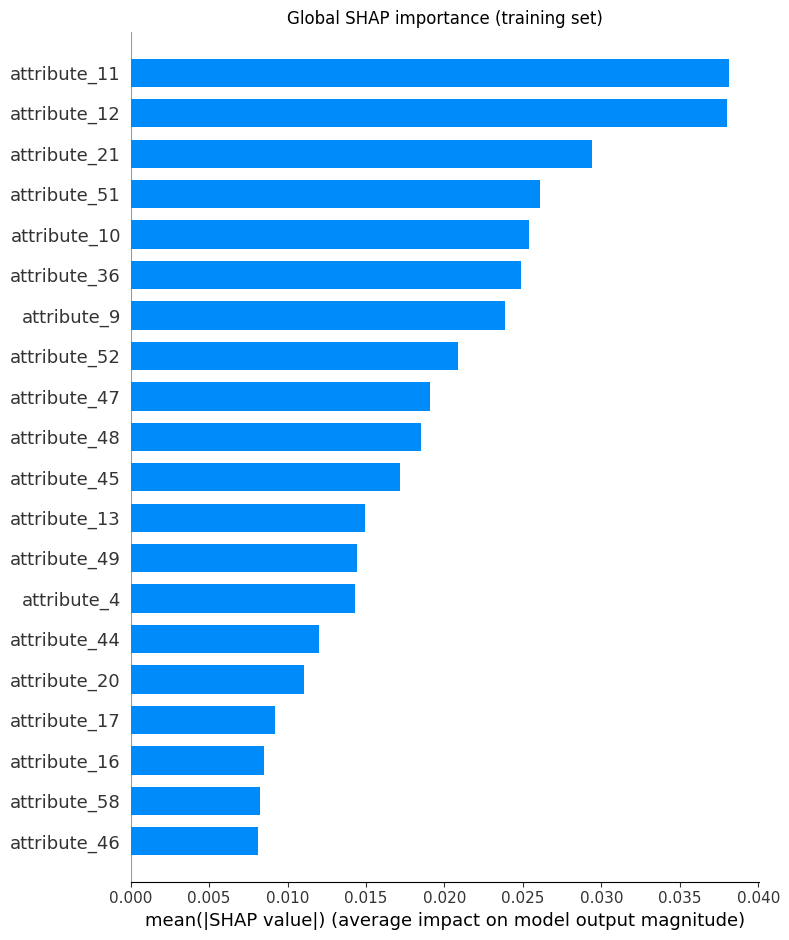

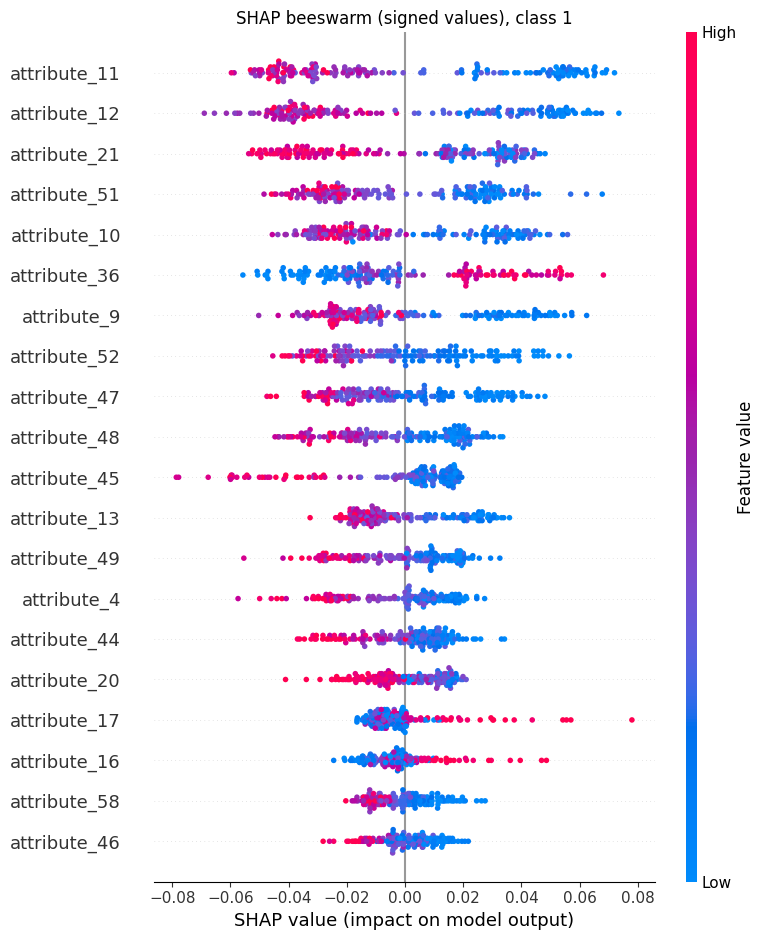

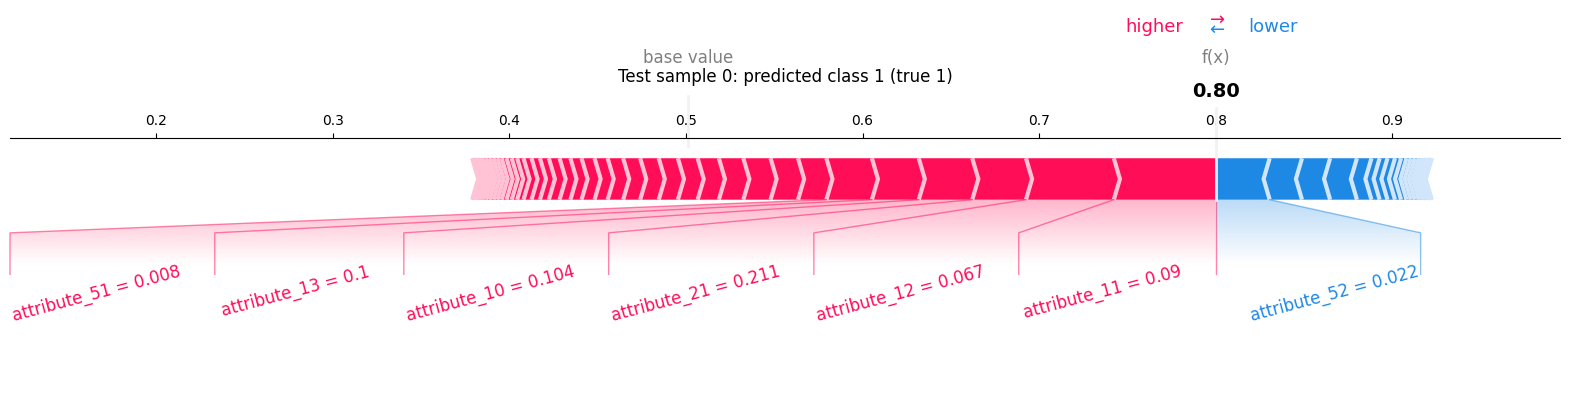

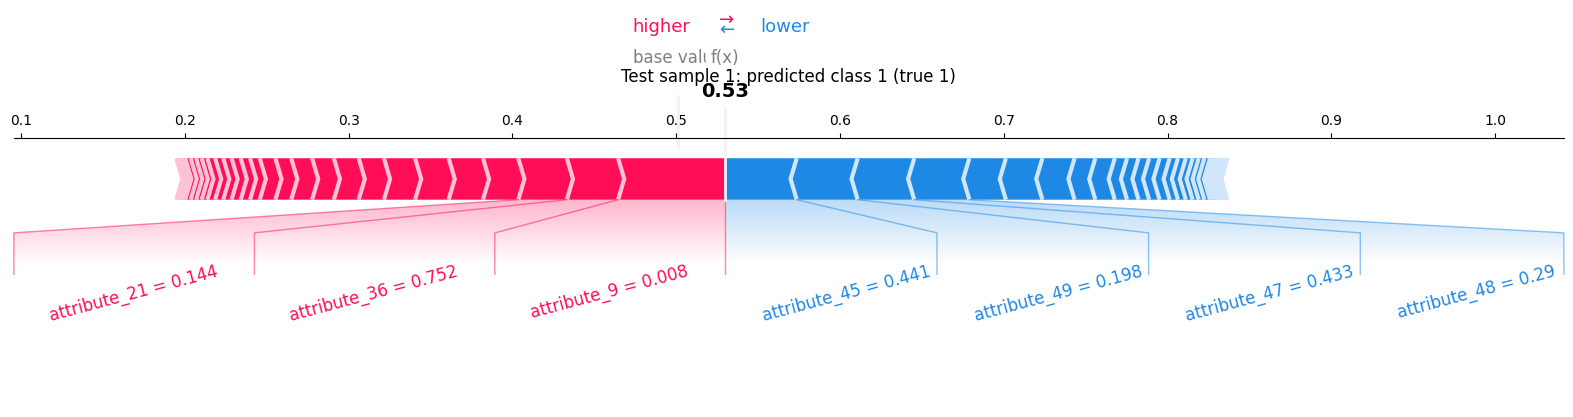

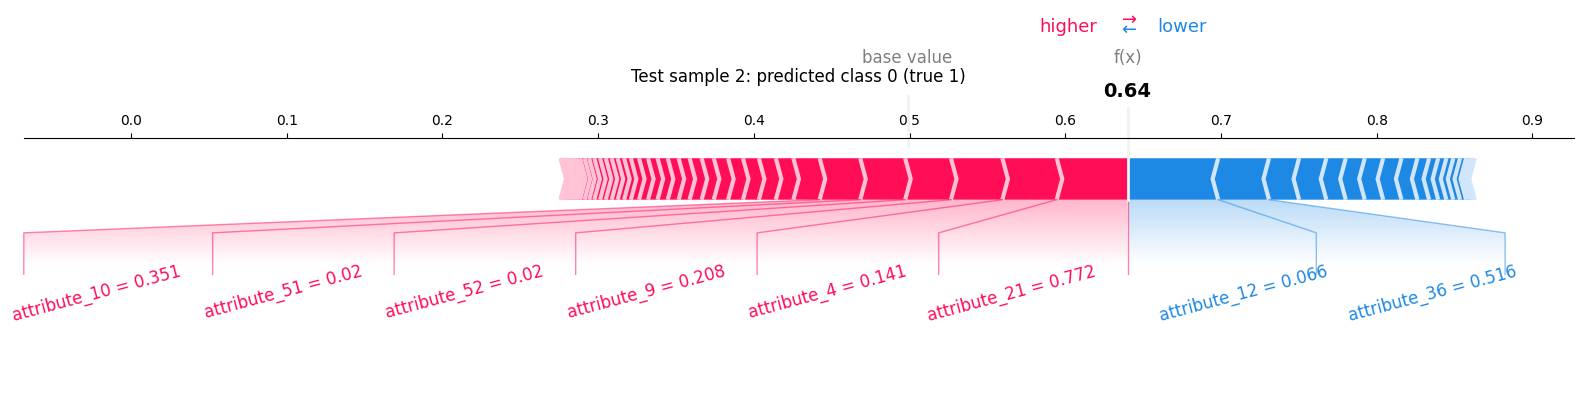

In [ ]:
# Note for reviewer:
# - SHAP values are computed on the TRAINING set only (no test leakage).
# - Proxy model: RandomForest with CONFIG["shap_rf_trees"] trees
#   (scikit-learn default = 100), explained with TreeExplainer, which
#   gives exact SHAP values for tree ensembles (Lundberg et al., 2020).
# - Global importance = mean |SHAP| over samples and classes,
#   normalised to sum to 1. This vector (shap_norm_global) is used in
#   (1) the fitness (SHAP term) and (2) the SHAP-guided initialisation.
# - Plots: global bar plot, signed beeswarm per class (direction of
#   effect), and force plots for single test samples (local explanation).
# ============================================================

rf_shap = RandomForestClassifier(n_estimators=CONFIG["shap_rf_trees"], random_state=SEED,
                                 n_jobs=CONFIG["n_jobs"], class_weight="balanced")
rf_shap.fit(X_train_df, y_train)
shap_explainer = shap.TreeExplainer(rf_shap)
shap_values_train = shap_explainer.shap_values(X_train_df)


def signed_shap_for_class(values, class_index):
    """Return the (samples x features) signed SHAP matrix of one class (handles all SHAP output formats)."""
    if isinstance(values, list):
        return np.asarray(values[class_index], dtype=float)
    arr = np.asarray(values, dtype=float)
    if arr.ndim == 2:
        return arr
    return arr[:, :, class_index] if arr.shape[1] == N_FEATURES else arr[:, class_index, :]


shap_abs_train = np.mean([np.abs(signed_shap_for_class(shap_values_train, c))
                          for c in range(N_CLASSES)], axis=0)
shap_importance = shap_abs_train.mean(axis=0)
shap_norm_global = shap_importance / shap_importance.sum()

shap_table = (pd.DataFrame({"Feature": feature_names, "SHAP normalized": shap_norm_global})
              .sort_values("SHAP normalized", ascending=False)
              .head(CONFIG["top_features_shown"]).reset_index(drop=True))
top_k = max(1, int(np.ceil(CONFIG["shap_top_ratio"] * N_FEATURES)))
shap_table["Top p_h (favoured in SHAP init)"] = shap_table.index < top_k
display(shap_table.round(4))

# 1) Global importance (bar)
plt.figure()
shap.summary_plot(shap_abs_train, X_train_df, feature_names=feature_names, plot_type="bar",
                  show=False, max_display=CONFIG["top_features_shown"])
plt.title("Global SHAP importance (training set)")
plt.tight_layout(); plt.show()

# 2) Signed beeswarm per class
for c in ([1] if BINARY else range(min(N_CLASSES, CONFIG["beeswarm_max_classes"]))):
    plt.figure()
    shap.summary_plot(signed_shap_for_class(shap_values_train, c), X_train_df,
                      feature_names=feature_names, show=False,
                      max_display=CONFIG["top_features_shown"])
    plt.title(f"SHAP beeswarm (signed values), class {c}")
    plt.tight_layout(); plt.show()

# 3) Force plots for individual test samples (explanation only, not used in selection)
test_explanation = shap_explainer(X_test_df)
values = np.asarray(test_explanation.values)
base = np.asarray(test_explanation.base_values)
for s in range(CONFIG["force_plot_samples"]):
    predicted = int(rf_shap.predict(X_test_df.iloc[[s]])[0])
    sample_values = values[s, :, predicted] if values.ndim == 3 else values[s]
    base_value = base[s, predicted] if base.ndim == 2 else base[s]
    shap.force_plot(base_value, sample_values, X_test_df.iloc[s].round(3), matplotlib=True,
                    show=False, figsize=(20, 3.5), text_rotation=15)
    plt.title(f"Test sample {s}: predicted class {predicted} (true {int(y_test[s])})", pad=40)
    plt.show()

# Cell 6 — Hyperparameter tuning: library Default vs Greedy search

Tuning options: Default, Greedy | selection rule: cv_rule | 10 CV folds | 8 cores

XGBoost: default CV F1 = 0.8514 ± 0.0595
  XGBoost         | pass 1 | n_estimators      ->    default | best CV F1 0.8514 | 0.0 min
  XGBoost         | pass 1 | max_depth         ->    default | best CV F1 0.8514 | 0.0 min
  XGBoost         | pass 1 | learning_rate     ->    default | best CV F1 0.8514 | 0.1 min
  XGBoost         | pass 1 | subsample         ->    default | best CV F1 0.8514 | 0.1 min
  XGBoost         | pass 1 | colsample_bytree  ->    default | best CV F1 0.8514 | 0.1 min
  XGBoost         | pass 1 | reg_lambda        ->    default | best CV F1 0.8514 | 0.1 min
  XGBoost         | pass 1 | min_child_weight  ->    default | best CV F1 0.8514 | 0.1 min
XGBoost: 43 trials in 0.2 min

LightGBM: default CV F1 = 0.8330 ± 0.0403
  LightGBM        | pass 1 | n_estimators      ->        320 | best CV F1 0.8481 | 0.0 min
  LightGBM        | pass 1 | max_depth         ->    default | best CV F1 0

,Model,Option,Trials,CV F1,CV std,Test F1 (info only),Chosen
0,XGBoost,Default,1,0.8514,0.0595,0.9280,True
1,XGBoost,Greedy,43,0.8514,0.0595,0.9280,False
2,LightGBM,Default,1,0.8330,0.0403,0.8799,True
3,LightGBM,Greedy,95,0.8604,0.0340,0.8531,False
4,CatBoost,Default,1,0.8559,0.0431,0.9034,True
5,CatBoost,Greedy,48,0.8811,0.0629,0.8531,False
6,Fitness XGBoost,Default,1,0.8514,0.0595,0.9280,True
7,Fitness XGBoost,Greedy,70,0.8545,0.0598,0.8531,False



Parameters used in the experiment:
  XGBoost          -> Default (library defaults)
  LightGBM         -> Default (library defaults)
  CatBoost         -> Default (library defaults)
  Fitness XGBoost  -> Default (library defaults)


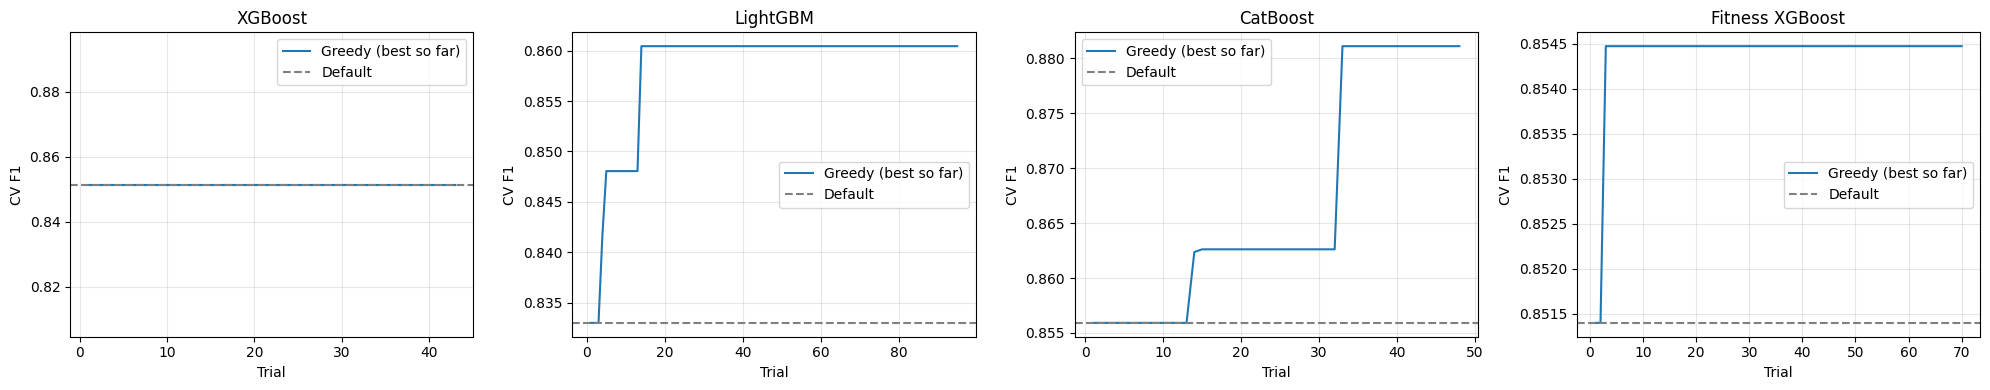

In [ ]:
# ============================================================
# Cell 6 — Hyperparameter tuning: library Default vs Greedy search
# ------------------------------------------------------------
# Note for reviewer:
# - Two options are compared for each model:
#   (1) Default : the library's own default parameters.
#   (2) Greedy  : greedy coordinate search. Starting from the default,
#       ONE parameter at a time is set to the best of `grid_points`
#       candidate values (linear or log-spaced within the search space),
#       while all other parameters stay fixed. Repeated for up to
#       `max_passes` passes; stops early if a pass brings no gain.
# - Score: weighted F1 of repeated stratified K-fold CV
#   (cv_folds x cv_repeats) on the TRAIN set, all features.
#   The test set is NOT used for the decision (shown for info only).
# - Selection rule "cv_rule": Greedy is used only if its CV gain over
#   the default is larger than the default's CV standard deviation;
#   otherwise the default is kept (protection against over-tuning).
# - Implementation: the CV folds of all candidate values of one
#   parameter are evaluated in parallel on all cores. The folds are
#   fixed (same seed), so results are identical to a sequential run.
# ============================================================

TUNE = CONFIG["tuning"]
TARGETS = list(CONFIG["search_spaces"])
CV_TUNE = RepeatedStratifiedKFold(n_splits=TUNE["cv_folds"], n_repeats=TUNE["cv_repeats"], random_state=SEED)
FOLDS = list(CV_TUNE.split(X_train, y_train))


def fold_score(target, params, fold):
    train_idx, valid_idx = FOLDS[fold]
    model = make_model(target, params).fit(X_train[train_idx], y_train[train_idx])
    pred = np.asarray(model.predict(X_train[valid_idx])).reshape(-1)
    return f1_score(y_train[valid_idx], pred, average="weighted")


def cv_scores_batch(target, param_list):
    """CV mean/std of several parameter sets; all (parameter set x fold) fits run in parallel."""
    scores = Parallel(n_jobs=CONFIG["n_jobs"])(
        delayed(fold_score)(target, p, f) for p in param_list for f in range(len(FOLDS)))
    scores = np.asarray(scores).reshape(len(param_list), len(FOLDS))
    return [(float(s.mean()), float(s.std())) for s in scores]


def candidate_values(kind, low, high, log, n_points):
    values = np.geomspace(low, high, n_points) if log else np.linspace(low, high, n_points)
    return sorted({int(round(v)) for v in values}) if kind == "int" else [float(v) for v in values]


def greedy_search(target, cfg=CONFIG):
    g = cfg["greedy_tuning"]
    space = cfg["search_spaces"][target]
    current = {**cfg["default_params"][target], **cfg["fixed_params"][target]}
    start = time.perf_counter()
    rows = []

    def record(param_list, results):
        for p, (mean, std) in zip(param_list, results):
            rows.append({"trial": len(rows) + 1, "cv_f1": mean, "cv_std": std,
                         "elapsed": time.perf_counter() - start, "params": dict(p)})

    first = cv_scores_batch(target, [current])
    record([current], first)
    best_score = first[0][0]
    for pass_id in range(1, g["max_passes"] + 1):
        improved = False
        for name, (kind, low, high, log) in space.items():
            candidates = [v for v in candidate_values(kind, low, high, log, g["grid_points"])
                          if v != current.get(name)]
            param_list = [{**current, name: v} for v in candidates]
            results = cv_scores_batch(target, param_list)
            record(param_list, results)
            means = [m for m, _ in results]
            if means and max(means) > best_score:
                i = int(np.argmax(means))
                best_score, current[name], improved = means[i], candidates[i], True
            print(f"  {target:15s} | pass {pass_id} | {name:17s} -> {current.get(name, 'default')!s:>10} "
                  f"| best CV F1 {best_score:.4f} | {(time.perf_counter() - start)/60:.1f} min", flush=True)
        if not improved:
            break
    return rows


# --- run: Default and Greedy for every model -----------------------------
print("Tuning options: Default, Greedy | selection rule:", CONFIG["tuning_selection"],
      f"| {len(FOLDS)} CV folds | {CONFIG['n_jobs']} cores")
start = time.perf_counter()
trials, defaults = {}, {}
for t in TARGETS:
    t0 = time.perf_counter()
    defaults[t] = cv_scores_batch(t, [CONFIG["default_params"][t]])[0]
    print(f"\n{t}: default CV F1 = {defaults[t][0]:.4f} ± {defaults[t][1]:.4f}")
    trials[t] = pd.DataFrame(greedy_search(t))
    print(f"{t}: {len(trials[t])} trials in {(time.perf_counter() - t0)/60:.1f} min")
print(f"\nTuning finished in {(time.perf_counter() - start) / 60:.1f} min")

# --- results table ---------------------------------------------------------
tuning_rows = []
for t in TARGETS:
    d_mean, d_std = defaults[t]
    tuning_rows.append({"Model": t, "Option": "Default", "Trials": 1, "CV F1": d_mean, "CV std": d_std,
                        "params": CONFIG["default_params"][t]})
    best = trials[t].loc[trials[t]["cv_f1"].idxmax()]
    tuning_rows.append({"Model": t, "Option": "Greedy", "Trials": len(trials[t]), "CV F1": best["cv_f1"],
                        "CV std": best["cv_std"], "params": best["params"]})
tuning_df = pd.DataFrame(tuning_rows)

# Test F1 (all features) — for information only, NOT used for selection
tuning_df["Test F1 (info only)"] = [
    test_scores(make_model(r["Model"], r["params"]), X_train, X_test)["F1"] for _, r in tuning_df.iterrows()]

# --- selection -------------------------------------------------------------
chosen = {}
for target, group in tuning_df.groupby("Model", sort=False):
    default = group[group["Option"] == "Default"].iloc[0]
    greedy = group[group["Option"] == "Greedy"].iloc[0]
    if CONFIG["tuning_selection"] == "cv_rule":
        gain = greedy["CV F1"] - default["CV F1"]
        keep_default = gain <= 0 or (TUNE["keep_default_if_within_std"] and gain < default["CV std"])
        chosen[target] = default if keep_default else greedy
    else:                                    # forced: "Default" or "Greedy"
        chosen[target] = group[group["Option"] == CONFIG["tuning_selection"]].iloc[0]
tuning_df["Chosen"] = [chosen[r["Model"]]["Option"] == r["Option"] for _, r in tuning_df.iterrows()]

TUNED_PARAMS = {t: dict(chosen[t]["params"]) for t in TARGETS}
EVAL_PARAMS = {m: TUNED_PARAMS[m] for m in CONFIG["eval_models"]}
FITNESS_PARAMS = TUNED_PARAMS["Fitness XGBoost"]

display(tuning_df.drop(columns="params").round(4))
print("\nParameters used in the experiment:")
for t in TARGETS:
    shown = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in TUNED_PARAMS[t].items()}
    print(f"  {t:16s} -> {chosen[t]['Option']:7s} {shown if shown else '(library defaults)'}")

# --- greedy progress vs default --------------------------------------------
fig, axes = plt.subplots(1, len(TARGETS), figsize=(5 * len(TARGETS), 4))
for ax, t in zip(np.atleast_1d(axes), TARGETS):
    ax.plot(trials[t]["trial"], trials[t]["cv_f1"].cummax(), label="Greedy (best so far)")
    ax.axhline(defaults[t][0], linestyle="--", color="gray", label="Default")
    ax.set(title=t, xlabel="Trial", ylabel="CV F1"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

# Cell 7 — Fitness functions

In [ ]:
# Note for reviewer:
#   fitness = w_error      * (1 - F1_cv)
#           + w_size       * (N_selected / N_total)
#           + w_shap_loss  * (1 - SHAP_norm(selected))
#           + w_redundancy * mean |Pearson corr| among selected features
# - F1_cv: weighted F1 of CONFIG["fitness_cv_folds"]-fold stratified CV
#   of the fitness XGBoost on the TRAIN set only.
# - SHAP_norm(selected): sum of the normalised SHAP importance of the
#   selected features (between 0 and 1), from Cell 5.
# - AvgAbsCorr: mean absolute Pearson correlation over all pairs of
#   selected features (train set), 0 if fewer than 2 features.
# - Weights come from CONFIG["fitness_weights"] (each set sums to 1).
#   classic2 has w_shap_loss = w_redundancy = 0, i.e. no SHAP information.
# - An empty subset receives CONFIG["empty_subset_penalty"].
# - Identical subsets are cached within a run (same value, no re-training),
#   but every call is still counted against the evaluation budget.
# ============================================================

CORR_TRAIN = np.abs(np.nan_to_num(np.corrcoef(X_train, rowvar=False)))
np.fill_diagonal(CORR_TRAIN, 0.0)
FITNESS_KINDS = list(CONFIG["fitness_weights"])


def make_fitness_functions(seed, cfg=CONFIG):
    """Return {fitness_name: f(vector) -> (value, details)} for one run (own cache, own CV seed)."""
    cache = {}
    cv = StratifiedKFold(n_splits=cfg["fitness_cv_folds"], shuffle=True, random_state=seed)

    def cv_error(idx):
        key = idx.tobytes()
        if key not in cache:
            scores = cross_val_score(make_model("Fitness XGBoost", FITNESS_PARAMS, seed),
                                     X_train[:, idx], y_train, cv=cv,
                                     scoring="f1_weighted", n_jobs=1)
            cache[key] = float(1.0 - scores.mean())
        return cache[key]

    def score(vec, kind):
        idx = np.flatnonzero(np.asarray(vec) >= cfg["threshold"])
        if idx.size == 0:
            return cfg["empty_subset_penalty"], {"f1": 0.0, "shap_norm": 0.0, "avg_corr": 0.0}
        error = cv_error(idx)
        shap_norm = float(shap_norm_global[idx].sum())
        avg_corr = (float(CORR_TRAIN[np.ix_(idx, idx)][np.triu_indices(idx.size, 1)].mean())
                    if idx.size > 1 else 0.0)
        terms = {"error": error,
                 "size": idx.size / N_FEATURES,
                 "shap_loss": 1.0 - shap_norm,
                 "redundancy": avg_corr}
        w = cfg["fitness_weights"][kind]
        value = float(sum(w[k] * terms[k] for k in terms))
        return value, {"f1": 1.0 - error, "shap_norm": shap_norm, "avg_corr": avg_corr}

    return {kind: (lambda vec, k=kind: score(vec, k)) for kind in FITNESS_KINDS}


class CountingFitness:
    """Wraps a fitness function and counts every evaluation (budget control)."""
    def __init__(self, fn):
        self.fn, self.n_evals = fn, 0

    def __call__(self, vec):
        self.n_evals += 1
        return self.fn(vec)


# --- sanity check: all features vs top-SHAP features --------------------
_fns = make_fitness_functions(SEED)
_all = np.ones(N_FEATURES)
_top = np.zeros(N_FEATURES)
_top[np.argsort(-shap_norm_global)[:max(1, int(np.ceil(CONFIG["shap_top_ratio"] * N_FEATURES)))]] = 1
rows = []
for kind in FITNESS_KINDS:
    for label, vec in [(f"all {N_FEATURES} features", _all), ("top-SHAP features", _top)]:
        val, det = _fns[kind](vec)
        rows.append({"Fitness": kind, "Subset": label, "Fitness value": val, **det})
print("Fitness check (lower is better):")
display(pd.DataFrame(rows).round(4))

Fitness check (lower is better):


,Fitness,Subset,Fitness value,f1,shap_norm,avg_corr
0,classic2,all 60 features,0.4799,0.8668,1.0000,0.2387
1,classic2,top-SHAP features,0.2257,0.8239,0.6514,0.2749
2,scenario_A,all 60 features,0.1999,0.8668,1.0000,0.2387
3,scenario_A,top-SHAP features,0.2282,0.8239,0.6514,0.2749
4,scenario_B,all 60 features,0.2143,0.8668,1.0000,0.2387
5,scenario_B,top-SHAP features,0.2428,0.8239,0.6514,0.2749


# Cell 8 — Differential Evolution with switchable components

In [ ]:
def repair_bounds(vector, rng):
    vector = vector.copy()
    bad = (vector < 0.0) | (vector > 1.0)
    vector[bad] = rng.random(int(bad.sum()))
    return vector


def make_population(init, pop_size, rng, cfg=CONFIG):
    if init == "random":
        return rng.random((pop_size, N_FEATURES))
    ratios = cfg["init_ratios_hybrid"] if init == "hybrid" else cfg["init_ratios_shap"]
    n_shap = int(round(ratios["shap"] * pop_size))
    n_opp_shap = min(n_shap, int(round(ratios.get("opp_shap", 0.0) * pop_size)))
    n_opp_random = int(round(ratios.get("opp_random", 0.0) * pop_size))
    n_random = pop_size - n_shap - n_opp_shap - n_opp_random

    top_k = max(1, int(np.ceil(cfg["shap_top_ratio"] * N_FEATURES)))
    top_idx = np.argsort(-shap_norm_global)[:top_k]
    random_part = rng.random((n_random, N_FEATURES))
    shap_part = rng.uniform(*cfg["shap_low_range"], (n_shap, N_FEATURES))
    shap_part[:, top_idx] = rng.uniform(*cfg["shap_high_range"], (n_shap, top_k))
    return np.vstack([random_part, shap_part,
                      1.0 - shap_part[:n_opp_shap],
                      1.0 - random_part[:n_opp_random]])


def opposition_jump(population, fitness, F, CR, fitness_fn):
    low, high = population.min(axis=0), population.max(axis=0)
    opposite = low + high - population
    union = np.vstack([population, opposite])
    union_fitness = np.concatenate([fitness, [fitness_fn(v)[0] for v in opposite]])
    keep = np.argsort(union_fitness, kind="stable")[:len(population)]
    return (union[keep], union_fitness[keep],
            np.concatenate([F, F])[keep], np.concatenate([CR, CR])[keep],
            int((keep >= len(population)).sum()))


def switchable_de(fitness_fn, init, obl, adaptive, pop_size, seed, cfg=CONFIG):
    rng = np.random.default_rng(seed)
    fitness_fn = CountingFitness(fitness_fn)
    start = time.perf_counter()
    budget = cfg["max_evals"]

    population = make_population(init, pop_size, rng, cfg)
    fitness = np.array([fitness_fn(v)[0] for v in population])
    if adaptive:
        F = cfg["F_low"] + rng.random(pop_size) * cfg["F_up"]
        CR = rng.random(pop_size)
    else:
        F, CR = np.full(pop_size, cfg["F_fixed"]), np.full(pop_size, cfg["CR_fixed"])

    history = [(fitness_fn.n_evals, float(fitness.min()))]
    generations, obl_kept = 0, 0
    while fitness_fn.n_evals + pop_size <= budget:
        generations += 1
        f_best, f_worst = float(fitness.min()), float(fitness.max())
        new_pop, new_fit, new_F, new_CR = population.copy(), fitness.copy(), F.copy(), CR.copy()
        for i in range(pop_size):
            F_try, CR_try = F[i], CR[i]
            if adaptive:
                tau = (cfg["degenerate_tau"] if np.isclose(f_best, f_worst)
                       else 1.0 - (fitness[i] - f_worst) / (f_best - f_worst))
                if rng.random() < tau:
                    F_try = cfg["F_low"] + rng.random() * cfg["F_up"]
                if rng.random() < tau:
                    CR_try = rng.random()
            r1, r2, r3 = rng.choice(np.delete(np.arange(pop_size), i), 3, replace=False)
            mutant = repair_bounds(population[r1] + F_try * (population[r2] - population[r3]), rng)
            cross = rng.random(N_FEATURES) <= CR_try
            cross[rng.integers(N_FEATURES)] = True
            trial = np.where(cross, mutant, population[i])
            trial_fitness = fitness_fn(trial)[0]
            if trial_fitness < fitness[i]:
                new_pop[i], new_fit[i], new_F[i], new_CR[i] = trial, trial_fitness, F_try, CR_try
        population, fitness, F, CR = new_pop, new_fit, new_F, new_CR
        if obl and rng.random() < cfg["jump_rate"] and fitness_fn.n_evals + pop_size <= budget:
            population, fitness, F, CR, kept = opposition_jump(population, fitness, F, CR, fitness_fn)
            obl_kept += kept
        history.append((fitness_fn.n_evals, float(fitness.min())))

    best = int(np.argmin(fitness))
    return {"mask": population[best] >= cfg["threshold"], "fitness": float(fitness[best]),
            "details": fitness_fn.fn(population[best])[1], "n_evals": fitness_fn.n_evals,
            "generations": generations, "obl_kept": obl_kept, "history": history,
            "search_time": time.perf_counter() - start}


# --- sanity check: composition of the starting populations -------------
_rng = np.random.default_rng(SEED)
for init in ["random", "shap", "hybrid"]:
    for pop_size in CONFIG["population_sizes"]:
        P = make_population(init, pop_size, _rng)
        assert P.shape == (pop_size, N_FEATURES) and P.min() >= 0 and P.max() <= 1
print("Starting populations OK for", CONFIG["population_sizes"])

Starting populations OK for [10, 20, 50, 100]


# Cell 9 — Method

In [ ]:
# Note for reviewer:
# Each method is the same DE (Cell 8) with different switches, so that
# every comparison isolates ONE change (all other settings identical:
# same budget, same population size, same seeds, same train/test split).
#
#  Main ladder (guideline method names):
#   1 Classic DE                          : classic2 fitness, random init
#   2 DE + Scenario B fitness             : + SHAP/redundancy fitness
#   3 DE + Scenario B + SHAP-guided init  : + SHAP-guided start population
#   4 ODE + Scenario B + hybrid SHAP init : + opposition (hybrid init with
#                                           opposite individuals + OBL jumping)
#   5 EvoX-FS                             : + self-adaptive F/CR (full method)
#
#  Side comparisons:
#   6 Classic DE + SHAP-guided init       : SHAP in the start population only
#                                           (fitness without SHAP) vs 1
#   7 EvoX-FS (Scenario A fitness)        : full method, fitness A    vs 5
#   8 EvoX-FS (classic2 fitness)          : full method, no SHAP term vs 5
#
# "previous" defines the paired comparison used in the statistics.
# Seeds: run r uses seed = CONFIG["seed"] + r - 1 for ALL methods
# (paired design for the Wilcoxon tests).
# ============================================================

METHODS = {
    "Classic DE":                          {"fitness": "classic2",   "init": "random", "obl": False, "adaptive": False, "previous": None},
    "DE + Scenario B fitness":             {"fitness": "scenario_B", "init": "random", "obl": False, "adaptive": False, "previous": "Classic DE"},
    "DE + Scenario B + SHAP-guided init":  {"fitness": "scenario_B", "init": "shap",   "obl": False, "adaptive": False, "previous": "DE + Scenario B fitness"},
    "ODE + Scenario B + hybrid SHAP init": {"fitness": "scenario_B", "init": "hybrid", "obl": True,  "adaptive": False, "previous": "DE + Scenario B + SHAP-guided init"},
    "EvoX-FS":                             {"fitness": "scenario_B", "init": "hybrid", "obl": True,  "adaptive": True,  "previous": "ODE + Scenario B + hybrid SHAP init"},
    "Classic DE + SHAP-guided init":       {"fitness": "classic2",   "init": "shap",   "obl": False, "adaptive": False, "previous": "Classic DE"},
    "EvoX-FS (Scenario A fitness)":        {"fitness": "scenario_A", "init": "hybrid", "obl": True,  "adaptive": True,  "previous": "EvoX-FS"},
    "EvoX-FS (classic2 fitness)":          {"fitness": "classic2",   "init": "hybrid", "obl": True,  "adaptive": True,  "previous": "EvoX-FS"},
}
EVOX = "EvoX-FS"
BASELINE = "Classic DE"
assert all(m["fitness"] in CONFIG["fitness_weights"] for m in METHODS.values())


def run_job(method, pop_size, run_id):
    seed = SEED + run_id - 1
    spec = METHODS[method]
    result = switchable_de(make_fitness_functions(seed)[spec["fitness"]],
                           spec["init"], spec["obl"], spec["adaptive"], pop_size, seed)
    rows = evaluate_subset(result["mask"], EVAL_PARAMS)
    for row in rows:
        row.update({"Method": method, "Population": pop_size, "Run": run_id, "Seed": seed,
                    "Fitness function": spec["fitness"], "Fitness": result["fitness"],
                    "Evaluations": result["n_evals"], "Generations": result["generations"],
                    "OBL kept": result["obl_kept"], "CV F1 (train)": result["details"]["f1"],
                    "SHAP_norm": result["details"]["shap_norm"], "Avg_Corr": result["details"]["avg_corr"],
                    "Search time (s)": result["search_time"]})
    return rows, {"method": method, "population": pop_size, "run": run_id,
                  "mask": result["mask"], "history": result["history"]}


display(pd.DataFrame(METHODS).T)
print("Total jobs:", len(METHODS), "methods x", len(CONFIG["population_sizes"]), "population sizes x",
      CONFIG["n_runs"], "runs =", len(METHODS) * len(CONFIG["population_sizes"]) * CONFIG["n_runs"])

,fitness,init,obl,adaptive,previous
Classic DE,classic2,random,False,False,None
DE + Scenario B fitness,scenario_B,random,False,False,Classic DE
DE + Scenario B + SHAP-guided init,scenario_B,shap,False,False,DE + Scenario B fitness
ODE + Scenario B + hybrid SHAP init,scenario_B,hybrid,True,False,DE + Scenario B + SHAP-guided init
EvoX-FS,scenario_B,hybrid,True,True,ODE + Scenario B + hybrid SHAP init
Classic DE + SHAP-guided init,classic2,shap,False,False,Classic DE
EvoX-FS (Scenario A fitness),scenario_A,hybrid,True,True,EvoX-FS
EvoX-FS (classic2 fitness),classic2,hybrid,True,True,EvoX-FS


Total jobs: 8 methods x 4 population sizes x 30 runs = 960


# Cell 11 — Main experiment: 8 methods x 4 population sizes x 30 runs

In [ ]:
# Note for reviewer:
# - 960 independent runs, each with exactly CONFIG["max_evals"]
#   fitness evaluations; runs are executed in parallel on all cores.
# - Every finished run is evaluated on the held-out test set with the
#   3 classifiers (Cell 4).
# - Checkpointing: results are saved to Google Drive every
#   CONFIG["checkpoint_rounds"] parallel rounds. If the session
#   disconnects, re-running the notebook continues from the saved runs.
# - Saved runs are reused ONLY if the experiment is unchanged: an MD5
#   fingerprint of the configuration, the model parameters actually used
#   and the method definitions names the checkpoint folder.
# ============================================================
import glob

EXECUTION_ONLY_KEYS = ("n_jobs", "results_dir", "checkpoint_rounds", "tuning", "greedy_tuning",
                       "tuning_selection", "search_spaces", "default_params", "fixed_params")
fingerprint = hashlib.md5(json.dumps(
    {"config": {k: v for k, v in CONFIG.items() if k not in EXECUTION_ONLY_KEYS},
     "eval": EVAL_PARAMS, "fitness": FITNESS_PARAMS, "methods": METHODS},
    sort_keys=True, default=str).encode()).hexdigest()[:10]
CKPT_DIR = os.path.join(CONFIG["results_dir"], f"checkpoints_{CONFIG['dataset']}_{fingerprint}")
os.makedirs(CKPT_DIR, exist_ok=True)
print("Experiment fingerprint:", fingerprint)
print("Checkpoint folder     :", CKPT_DIR)

# --- load finished runs (resume) ---------------------------------------
done = {}
for f in sorted(glob.glob(os.path.join(CKPT_DIR, "part_*.pkl"))):
    done.update(pd.read_pickle(f))

all_jobs = [(m, p, r) for p in CONFIG["population_sizes"] for m in METHODS
            for r in range(1, CONFIG["n_runs"] + 1)]
todo = [j for j in all_jobs if j not in done]
print(f"Runs finished: {len(done)} / {len(all_jobs)} | remaining: {len(todo)}")

# --- run the remaining jobs in checkpointed chunks ----------------------
chunk_size = CONFIG["n_jobs"] * CONFIG["checkpoint_rounds"]
t_start = time.perf_counter()
for c, start in enumerate(range(0, len(todo), chunk_size)):
    chunk = todo[start:start + chunk_size]
    out = Parallel(n_jobs=CONFIG["n_jobs"])(delayed(run_job)(*job) for job in chunk)
    part = dict(zip(chunk, out))
    pd.to_pickle(part, os.path.join(CKPT_DIR, f"part_{time.strftime('%Y%m%d_%H%M%S')}_{c:03d}.pkl"))
    done.update(part)

    finished = start + len(chunk)
    elapsed = time.perf_counter() - t_start
    eta = elapsed / finished * (len(todo) - finished)
    print(f"[{time.strftime('%H:%M:%S')}] saved {len(done)}/{len(all_jobs)} runs | "
          f"elapsed {elapsed/3600:.2f} h | remaining ≈ {eta/3600:.2f} h", flush=True)

# --- assemble all results -----------------------------------------------
all_rows, all_masks, all_histories = [], {}, {}
for job in all_jobs:
    rows, extra = done[job]
    all_rows.extend(rows)
    key = (extra["method"], extra["population"])
    all_masks.setdefault(key, []).append(extra["mask"])
    all_histories.setdefault(key, []).append(extra["history"])

experiment_df = pd.DataFrame(all_rows)
experiment_df.to_csv(OUT_PREFIX + "all_runs.csv", index=False)
print(f"\nAll {len(all_jobs)} runs available | rows: {len(experiment_df)} | saved {OUT_PREFIX}all_runs.csv")

# --- reference: no feature selection (all features) ---------------------
no_fs_df = pd.DataFrame(evaluate_subset(np.ones(N_FEATURES, dtype=bool), EVAL_PARAMS))
print("No feature selection (all features):")
display(no_fs_df.round(4))

Experiment fingerprint: 83d5d3c3e1
Checkpoint folder     : /content/drive/MyDrive/EvoXFS_results/checkpoints_sonar_83d5d3c3e1
Runs finished: 0 / 960 | remaining: 960
[20:23:04] saved 32/960 runs | elapsed 0.32 h | remaining ≈ 9.28 h
[20:50:59] saved 64/960 runs | elapsed 0.79 h | remaining ≈ 11.00 h
[21:14:40] saved 96/960 runs | elapsed 1.18 h | remaining ≈ 10.62 h
[21:38:07] saved 128/960 runs | elapsed 1.57 h | remaining ≈ 10.21 h
[21:59:38] saved 160/960 runs | elapsed 1.93 h | remaining ≈ 9.65 h
[22:17:56] saved 192/960 runs | elapsed 2.23 h | remaining ≈ 8.94 h
[22:39:01] saved 224/960 runs | elapsed 2.59 h | remaining ≈ 8.50 h
[23:00:43] saved 256/960 runs | elapsed 2.95 h | remaining ≈ 8.11 h
[23:28:35] saved 288/960 runs | elapsed 3.41 h | remaining ≈ 7.96 h
[23:57:06] saved 320/960 runs | elapsed 3.89 h | remaining ≈ 7.77 h
[00:24:55] saved 352/960 runs | elapsed 4.35 h | remaining ≈ 7.52 h
[00:51:54] saved 384/960 runs | elapsed 4.80 h | remaining ≈ 7.20 h
[01:15:35] saved 4

,Classifier,Features,Accuracy,F1,AUC,AUPRC
0,XGBoost,60,0.9286,0.9280,0.9818,0.9830
1,LightGBM,60,0.8810,0.8799,0.9705,0.9699
2,CatBoost,60,0.9048,0.9034,0.9909,0.9910


# Cell 12 — Convergence analysis

  figure saved: /content/drive/MyDrive/EvoXFS_results/figures/sonar_convergence_classic2.png


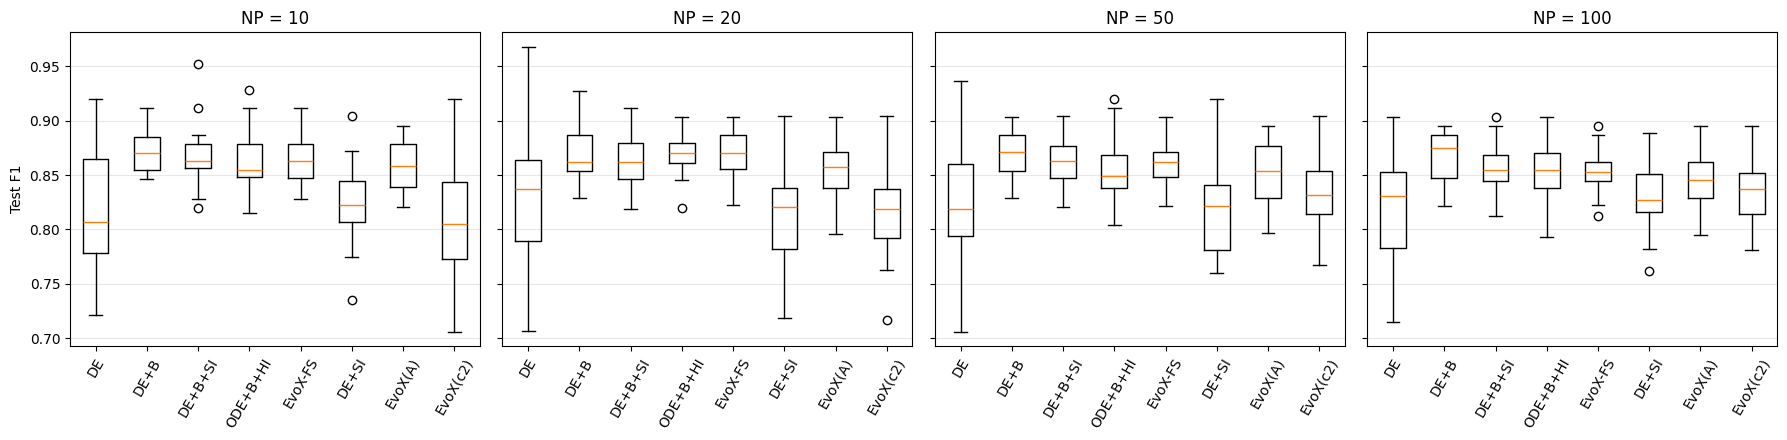

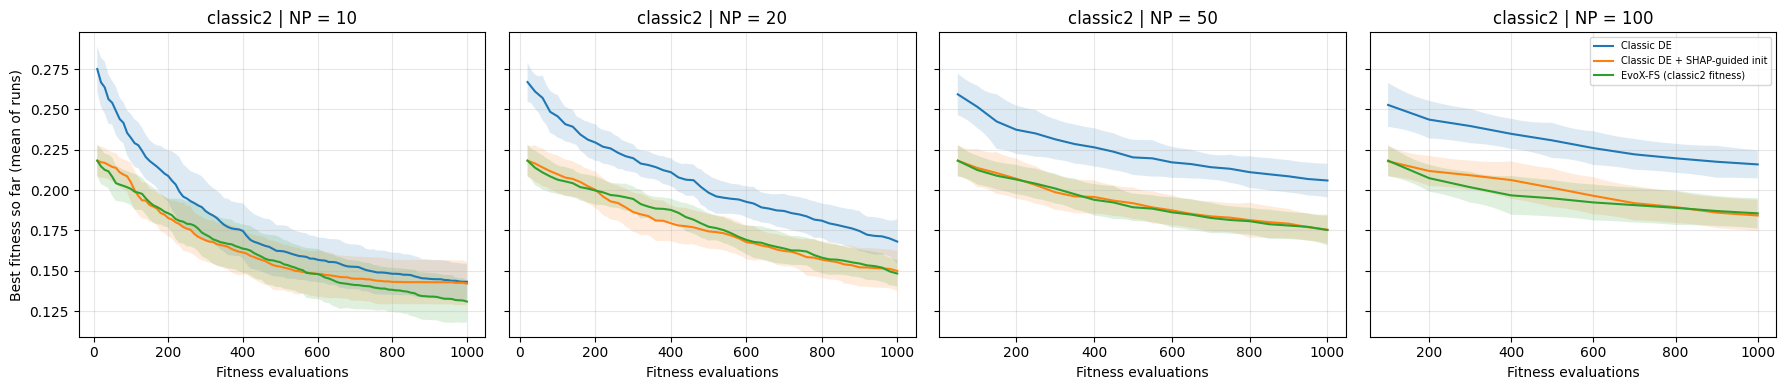

  figure saved: /content/drive/MyDrive/EvoXFS_results/figures/sonar_convergence_scenario_B.png


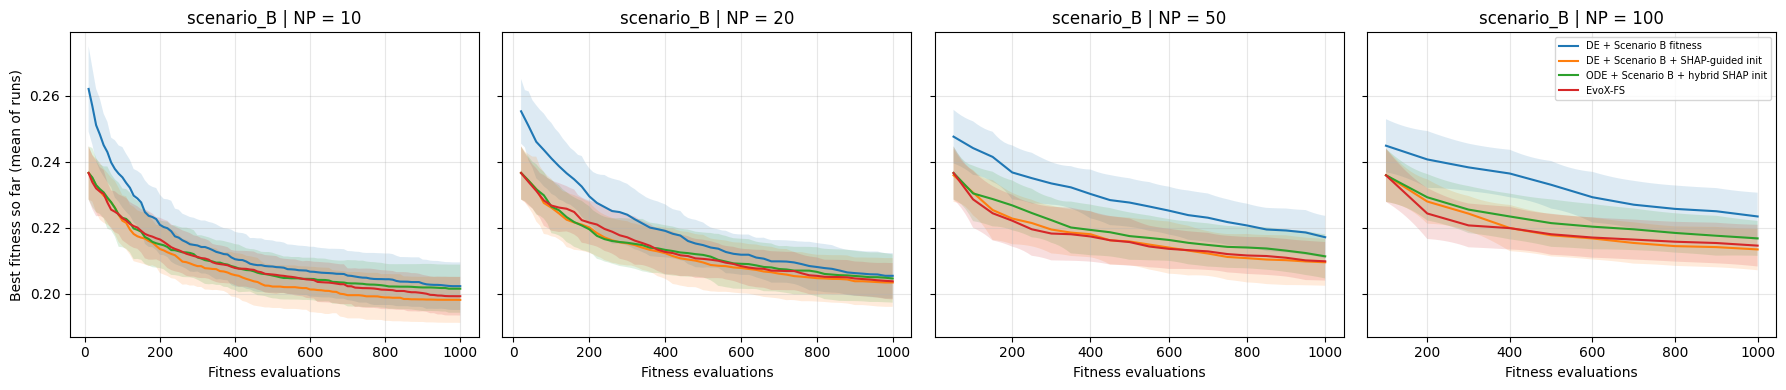

  figure saved: /content/drive/MyDrive/EvoXFS_results/figures/sonar_convergence_scenario_A.png


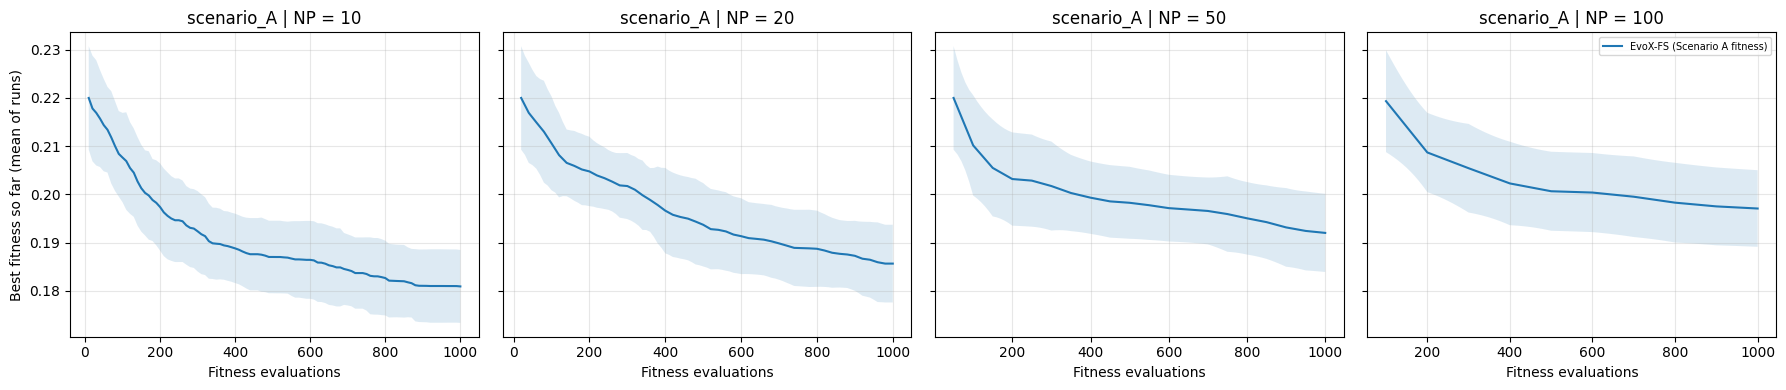

,Fitness function,Method,Population,Final fitness (mean),Final fitness (std),Evals to 99% (mean)
0,classic2,Classic DE,10,0.1432,0.0112,779.3333
1,classic2,Classic DE + SHAP-guided init,10,0.1421,0.0135,628.3333
2,classic2,EvoX-FS (classic2 fitness),10,0.1310,0.0128,848.0000
3,classic2,Classic DE,20,0.1681,0.0139,886.0000
4,classic2,Classic DE + SHAP-guided init,20,0.1499,0.0126,861.6667
5,classic2,EvoX-FS (classic2 fitness),20,0.1484,0.0082,882.6667
6,classic2,Classic DE,50,0.2059,0.0105,835.0000
7,classic2,Classic DE + SHAP-guided init,50,0.1755,0.0087,768.0000
8,classic2,EvoX-FS (classic2 fitness),50,0.1753,0.0096,790.0000
9,classic2,Classic DE,100,0.2159,0.0087,766.6667


In [ ]:
FIG_DIR = os.path.join(CONFIG["results_dir"], "figures")
os.makedirs(FIG_DIR, exist_ok=True)
FIG_DPI = 300                      # image resolution of saved figures (presentation only)


def save_fig(name):
    path = os.path.join(FIG_DIR, f"{CONFIG['dataset']}_{name}.png")
    plt.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    print("  figure saved:", path)


GRID = np.linspace(0, CONFIG["max_evals"], CONFIG["max_evals"] // min(CONFIG["population_sizes"]) + 1)
CONV_FRACTION = 0.99


def curves_for(method, pop_size):
    out = []
    for history in all_histories[(method, pop_size)]:
        evals, values = zip(*history)
        out.append(np.interp(GRID, evals, values, left=np.nan))
    return np.array(out)


def evals_to_fraction(curve, fraction):
    valid = ~np.isnan(curve)
    c, g = curve[valid], GRID[valid]
    target = c[0] - fraction * (c[0] - c[-1])
    return float(g[np.argmax(c <= target)]) if c[0] > c[-1] else float(g[0])


groups = {}
for m, spec in METHODS.items():
    groups.setdefault(spec["fitness"], []).append(m)

conv_rows, curve_rows = [], []
for fit_name, members in groups.items():
    fig, axes = plt.subplots(1, len(CONFIG["population_sizes"]),
                             figsize=(4.5 * len(CONFIG["population_sizes"]), 4), sharey=True)
    for ax, pop_size in zip(np.atleast_1d(axes), CONFIG["population_sizes"]):
        for m in members:
            C = curves_for(m, pop_size)
            mean, std = np.nanmean(C, axis=0), np.nanstd(C, axis=0)
            ax.plot(GRID, mean, label=m)
            ax.fill_between(GRID, mean - std, mean + std, alpha=0.15)
            speeds = [evals_to_fraction(c, CONV_FRACTION) for c in C]
            conv_rows.append({"Fitness function": fit_name, "Method": m, "Population": pop_size,
                              "Final fitness (mean)": float(np.nanmean(C[:, -1])),
                              "Final fitness (std)": float(np.nanstd(C[:, -1])),
                              f"Evals to {CONV_FRACTION:.0%} (mean)": float(np.mean(speeds))})
            curve_rows += [{"Method": m, "Population": pop_size, "Evaluations": e,
                            "Mean best fitness": v, "Std": s} for e, v, s in zip(GRID, mean, std)]
        ax.set(title=f"{fit_name} | NP = {pop_size}", xlabel="Fitness evaluations")
        ax.grid(alpha=0.3)
    np.atleast_1d(axes)[0].set_ylabel("Best fitness so far (mean of runs)")
    np.atleast_1d(axes)[-1].legend(fontsize=7)
    plt.tight_layout(); save_fig(f"convergence_{fit_name}"); plt.show()

convergence_df = pd.DataFrame(conv_rows)
convergence_curves_df = pd.DataFrame(curve_rows)
display(convergence_df.round(4))

# Cell 13 — Results: summary tables and main figures

Short labels used in the figures:
  DE        = Classic DE
  DE+B      = DE + Scenario B fitness
  DE+B+SI   = DE + Scenario B + SHAP-guided init
  ODE+B+HI  = ODE + Scenario B + hybrid SHAP init
  EvoX-FS   = EvoX-FS
  DE+SI     = Classic DE + SHAP-guided init
  EvoX(A)   = EvoX-FS (Scenario A fitness)
  EvoX(c2)  = EvoX-FS (classic2 fitness)


,Population,Method,F1_mean,F1_std,Accuracy_mean,AUC_mean,AUPRC_mean,Features_mean,Features_std,Generations,Time_s,Reduction (%)
0,10,Classic DE,0.8232,0.0560,0.8262,0.9047,0.9134,10.9667,2.0924,99.0000,251.2006,81.7222
1,10,DE + Scenario B fitness,0.8713,0.0155,0.8738,0.9694,0.9708,35.2333,3.5398,99.0000,392.6593,41.2778
2,10,DE + Scenario B + SHAP-guided init,0.8668,0.0250,0.8696,0.9635,0.9657,29.8667,3.7576,99.0000,322.8013,50.2222
3,10,ODE + Scenario B + hybrid SHAP init,0.8622,0.0262,0.8651,0.9631,0.9640,29.5333,4.7903,77.3000,316.3815,50.7778
4,10,EvoX-FS,0.8640,0.0198,0.8669,0.9659,0.9678,30.7333,3.1506,75.8667,345.2536,48.7778
5,10,Classic DE + SHAP-guided init,0.8245,0.0331,0.8272,0.9117,0.9219,11.0000,1.5086,99.0000,198.1917,81.6667
6,10,EvoX-FS (Scenario A fitness),0.8591,0.0228,0.8622,0.9605,0.9631,28.3000,4.1701,76.6000,327.8494,52.8333
7,10,EvoX-FS (classic2 fitness),0.8099,0.0479,0.8143,0.9061,0.9167,9.1333,1.8889,76.4667,265.1086,84.7778
8,20,Classic DE,0.8302,0.0592,0.8328,0.9223,0.9280,12.8333,2.3647,49.0000,361.6699,78.6111
9,20,DE + Scenario B fitness,0.8693,0.0233,0.8720,0.9675,0.9692,35.3333,3.6703,49.0000,430.0637,41.1111



Test F1 (mean ± std over 30 runs, averaged over 3 classifiers):


Population,10,20,50,100
Method,,,,
Classic DE,0.8232 ± 0.0560,0.8302 ± 0.0592,0.8266 ± 0.0529,0.8206 ± 0.0495
DE + Scenario B fitness,0.8713 ± 0.0155,0.8693 ± 0.0233,0.8698 ± 0.0193,0.8676 ± 0.0238
DE + Scenario B + SHAP-guided init,0.8668 ± 0.0250,0.8632 ± 0.0239,0.8633 ± 0.0235,0.8547 ± 0.0232
ODE + Scenario B + hybrid SHAP init,0.8622 ± 0.0262,0.8696 ± 0.0177,0.8544 ± 0.0268,0.8545 ± 0.0260
EvoX-FS,0.8640 ± 0.0198,0.8690 ± 0.0226,0.8624 ± 0.0218,0.8540 ± 0.0187
Classic DE + SHAP-guided init,0.8245 ± 0.0331,0.8152 ± 0.0415,0.8160 ± 0.0401,0.8300 ± 0.0307
EvoX-FS (Scenario A fitness),0.8591 ± 0.0228,0.8559 ± 0.0256,0.8515 ± 0.0271,0.8456 ± 0.0234
EvoX-FS (classic2 fitness),0.8099 ± 0.0479,0.8162 ± 0.0398,0.8359 ± 0.0354,0.8330 ± 0.0270


Selected features (mean ± std), out of 60 :


Population,10,20,50,100
Method,,,,
Classic DE,10.97 ± 2.09,12.83 ± 2.36,16.53 ± 1.28,18.33 ± 2.09
DE + Scenario B fitness,35.23 ± 3.54,35.33 ± 3.67,35.70 ± 4.10,35.00 ± 2.74
DE + Scenario B + SHAP-guided init,29.87 ± 3.76,31.10 ± 3.21,29.33 ± 3.46,27.50 ± 3.60
ODE + Scenario B + hybrid SHAP init,29.53 ± 4.79,32.47 ± 4.25,28.53 ± 5.07,27.23 ± 3.38
EvoX-FS,30.73 ± 3.15,30.50 ± 4.10,28.17 ± 4.28,25.43 ± 4.40
Classic DE + SHAP-guided init,11.00 ± 1.51,10.67 ± 1.90,13.87 ± 1.91,14.87 ± 2.03
EvoX-FS (Scenario A fitness),28.30 ± 4.17,28.97 ± 3.54,25.60 ± 4.70,24.80 ± 5.52
EvoX-FS (classic2 fitness),9.13 ± 1.89,10.77 ± 1.52,14.53 ± 1.76,15.70 ± 1.84


Test F1 per classifier:


Classifier,Population,Method,XGBoost,LightGBM,CatBoost
0,10,Classic DE,0.8157,0.8183,0.8356
1,10,DE + Scenario B fitness,0.8682,0.8622,0.8834
2,10,DE + Scenario B + SHAP-guided init,0.8593,0.8553,0.8858
3,10,ODE + Scenario B + hybrid SHAP init,0.8564,0.8453,0.8850
4,10,EvoX-FS,0.8586,0.8535,0.8799
5,10,Classic DE + SHAP-guided init,0.8031,0.8278,0.8426
6,10,EvoX-FS (Scenario A fitness),0.8481,0.8460,0.8833
7,10,EvoX-FS (classic2 fitness),0.8015,0.7962,0.8320
8,20,Classic DE,0.8198,0.8230,0.8478
9,20,DE + Scenario B fitness,0.8674,0.8513,0.8891


  figure saved: /content/drive/MyDrive/EvoXFS_results/figures/sonar_boxplot_f1.png


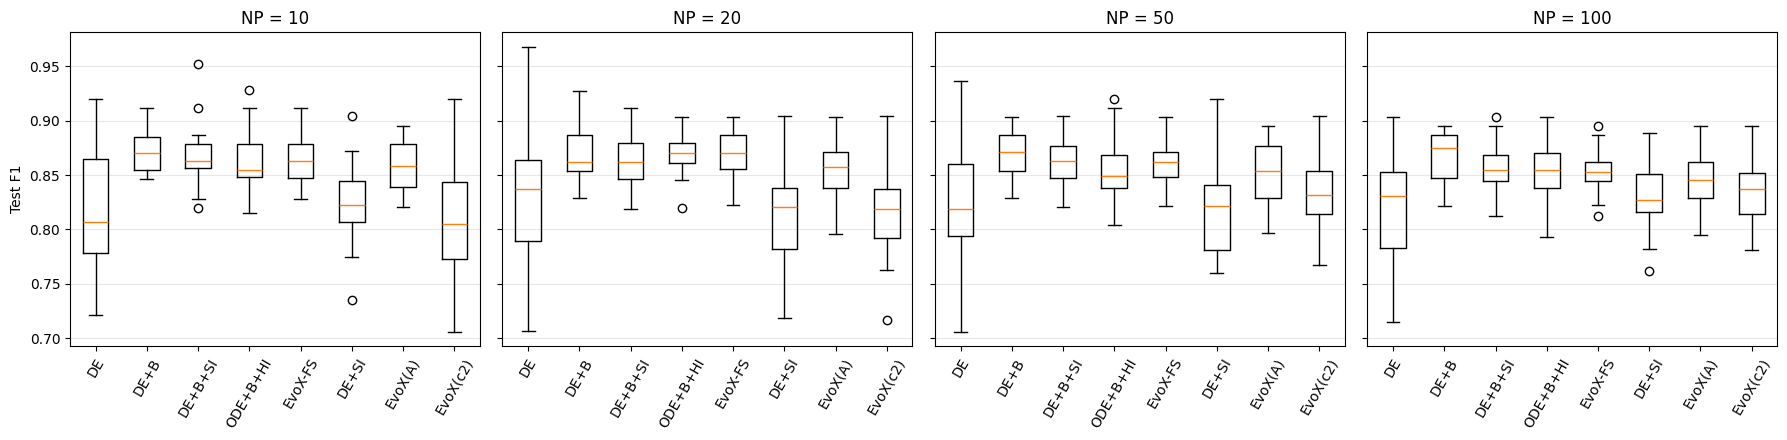

  figure saved: /content/drive/MyDrive/EvoXFS_results/figures/sonar_boxplot_features.png


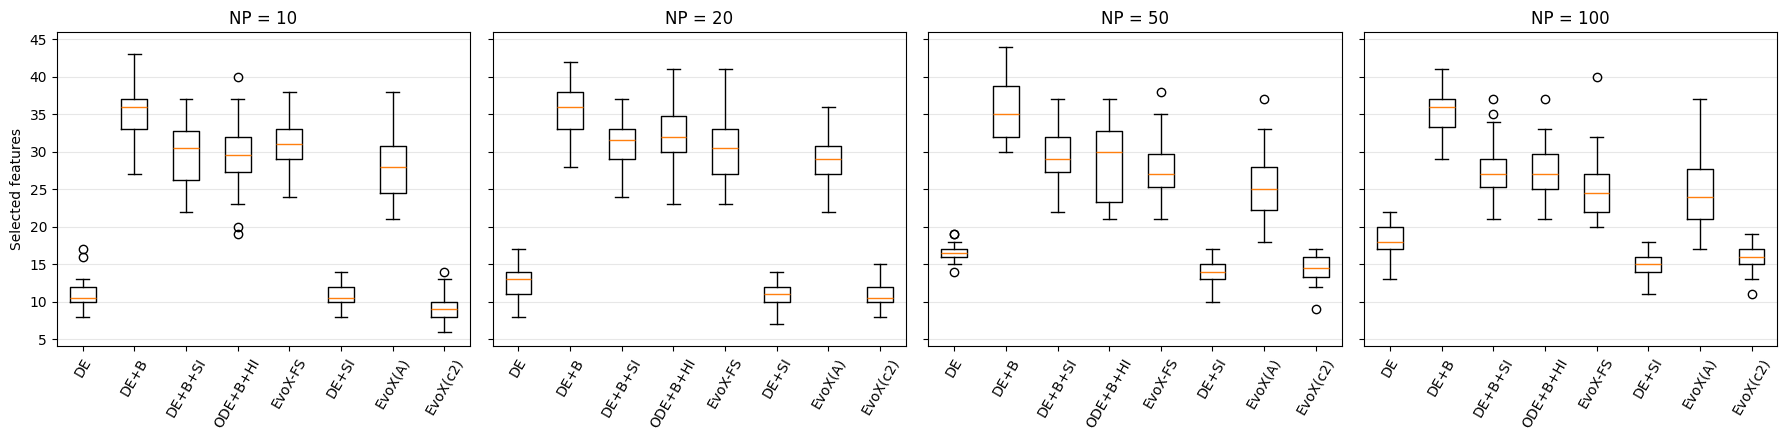

  figure saved: /content/drive/MyDrive/EvoXFS_results/figures/sonar_population_effect.png


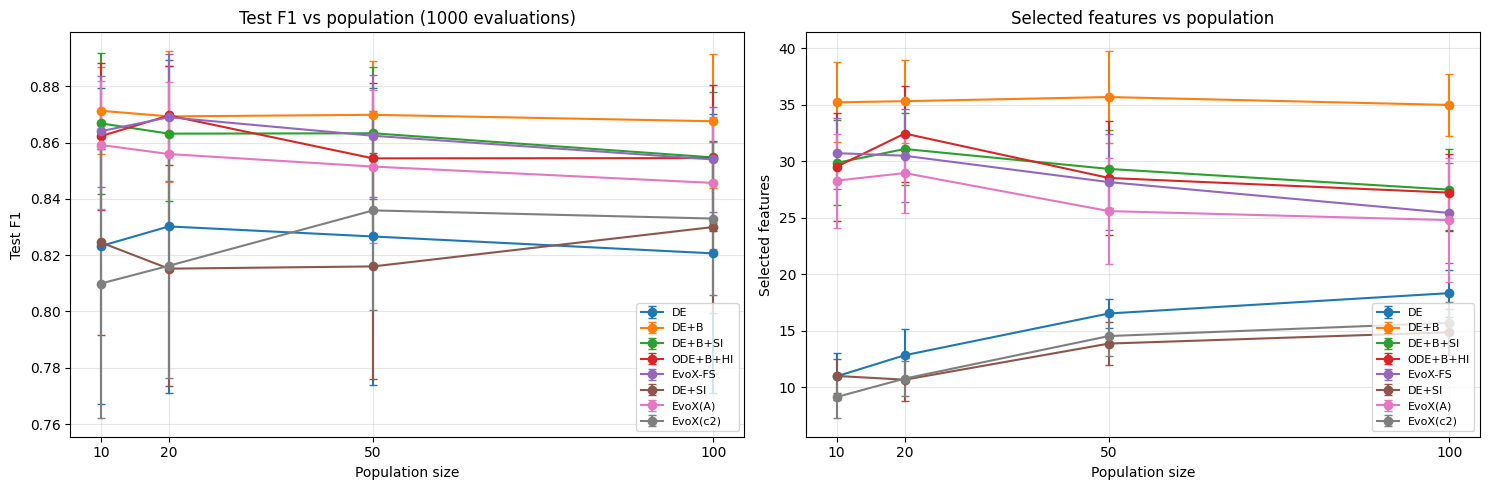

  figure saved: /content/drive/MyDrive/EvoXFS_results/figures/sonar_selection_frequency.png


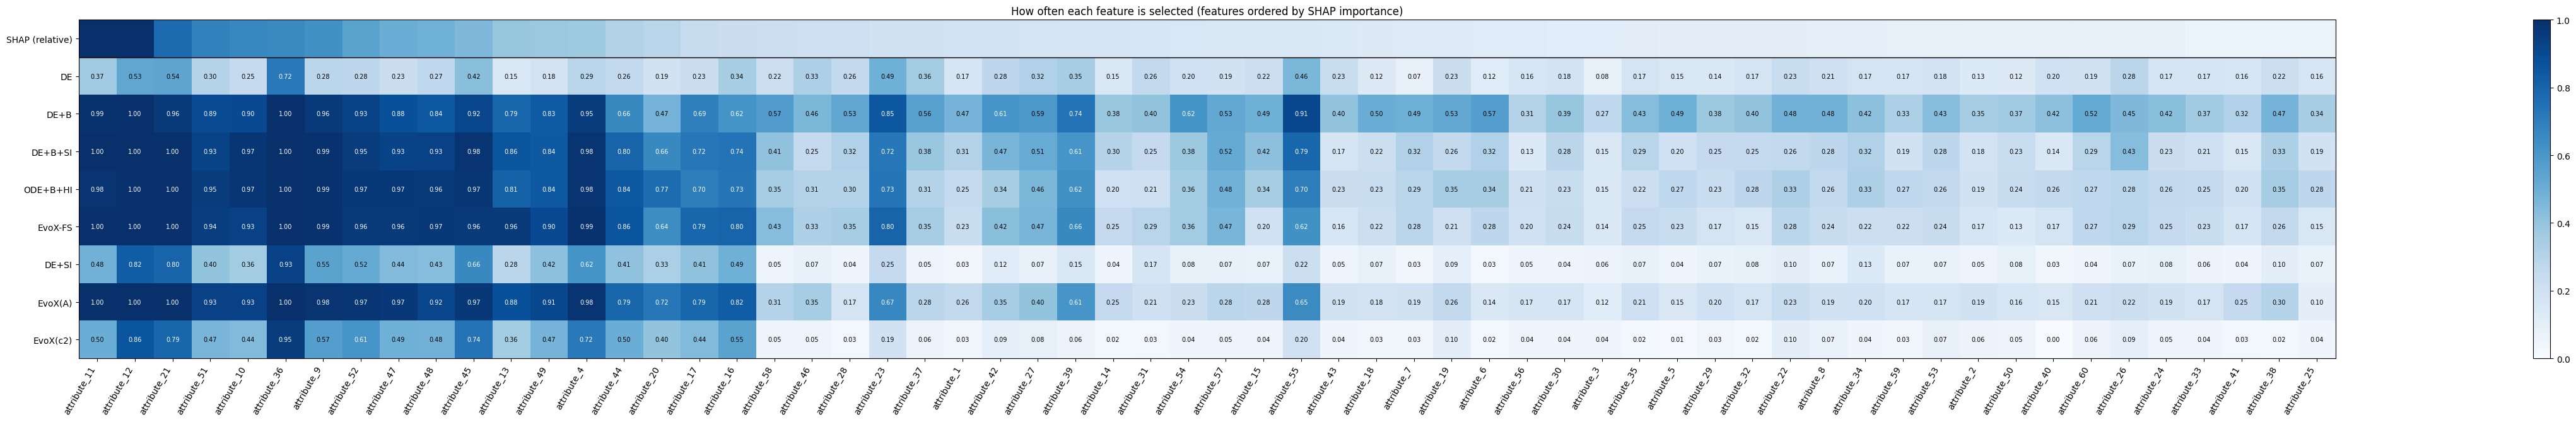

  figure saved: /content/drive/MyDrive/EvoXFS_results/figures/sonar_f1_vs_features.png


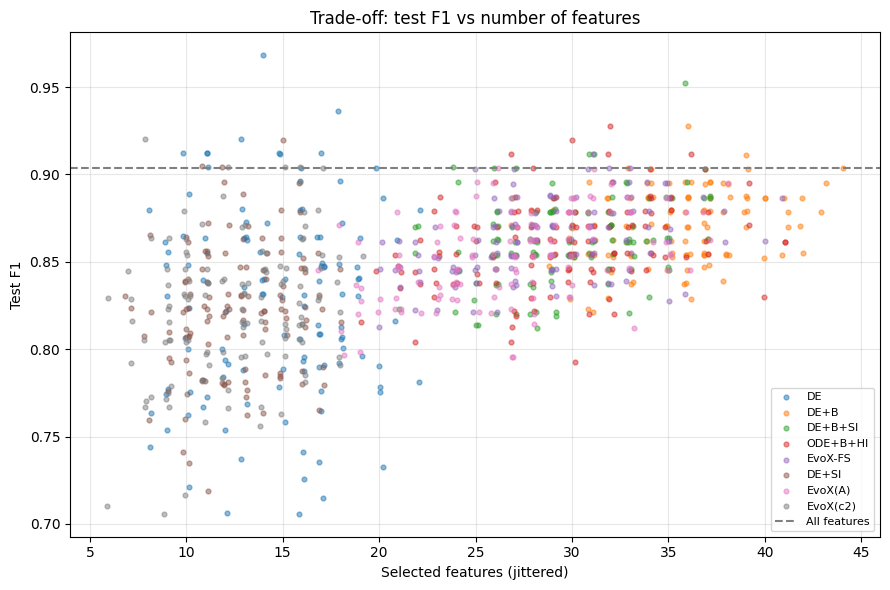

In [ ]:

METRICS = ["Accuracy", "F1", "AUC", "AUPRC"]
SHORT = {"Classic DE": "DE", "DE + Scenario B fitness": "DE+B",
         "DE + Scenario B + SHAP-guided init": "DE+B+SI", "ODE + Scenario B + hybrid SHAP init": "ODE+B+HI",
         "EvoX-FS": "EvoX-FS", "Classic DE + SHAP-guided init": "DE+SI",
         "EvoX-FS (Scenario A fitness)": "EvoX(A)", "EvoX-FS (classic2 fitness)": "EvoX(c2)"}
print("Short labels used in the figures:")
for m, s in SHORT.items():
    print(f"  {s:9s} = {m}")

per_run = (experiment_df.groupby(["Population", "Method", "Run"], sort=False)
           [["Features", *METRICS, "CV F1 (train)", "Generations", "OBL kept", "Search time (s)"]]
           .mean().reset_index())

summary = per_run.groupby(["Population", "Method"], sort=False).agg(
    F1_mean=("F1", "mean"), F1_std=("F1", "std"),
    Accuracy_mean=("Accuracy", "mean"), AUC_mean=("AUC", "mean"), AUPRC_mean=("AUPRC", "mean"),
    Features_mean=("Features", "mean"), Features_std=("Features", "std"),
    Generations=("Generations", "mean"), Time_s=("Search time (s)", "mean")).reset_index()
summary["Reduction (%)"] = 100 * (1 - summary["Features_mean"] / N_FEATURES)
display(summary.round(4))

# Report-ready tables: "mean ± std"
fmt = lambda m, s, d: f"{m:.{d}f} ± {s:.{d}f}"
summary["F1 (mean ± std)"] = [fmt(m, s, 4) for m, s in zip(summary["F1_mean"], summary["F1_std"])]
summary["Features (mean ± std)"] = [fmt(m, s, 2) for m, s in zip(summary["Features_mean"], summary["Features_std"])]
print("\nTest F1 (mean ± std over 30 runs, averaged over 3 classifiers):")
display(summary.pivot(index="Method", columns="Population", values="F1 (mean ± std)").loc[list(METHODS)])
print("Selected features (mean ± std), out of", N_FEATURES, ":")
display(summary.pivot(index="Method", columns="Population", values="Features (mean ± std)").loc[list(METHODS)])

per_classifier = (experiment_df.groupby(["Population", "Method", "Classifier"], sort=False)["F1"]
                  .mean().unstack("Classifier").reset_index())
print("Test F1 per classifier:")
display(per_classifier.round(4))

POPS = CONFIG["population_sizes"]
labels = [SHORT[m] for m in METHODS]


def paired(metric, pop_size, method):
    return (per_run[(per_run["Population"] == pop_size) & (per_run["Method"] == method)]
            .sort_values("Run")[metric].to_numpy())


# (a, b) box plots of F1 and number of features
for metric, ylabel in [("F1", "Test F1"), ("Features", "Selected features")]:
    fig, axes = plt.subplots(1, len(POPS), figsize=(4.5 * len(POPS), 4.5), sharey=True)
    for ax, p in zip(np.atleast_1d(axes), POPS):
        ax.boxplot([paired(metric, p, m) for m in METHODS], tick_labels=labels)
        ax.set(title=f"NP = {p}"); ax.tick_params(axis="x", rotation=60); ax.grid(axis="y", alpha=0.3)
    np.atleast_1d(axes)[0].set_ylabel(ylabel)
    plt.tight_layout(); save_fig(f"boxplot_{metric.lower()}"); plt.show()

# (c) population-size effect
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for m in METHODS:
    s = summary[summary["Method"] == m]
    axes[0].errorbar(s["Population"], s["F1_mean"], yerr=s["F1_std"], marker="o", capsize=3, label=SHORT[m])
    axes[1].errorbar(s["Population"], s["Features_mean"], yerr=s["Features_std"], marker="o", capsize=3, label=SHORT[m])
axes[0].set(xlabel="Population size", ylabel="Test F1", title=f"Test F1 vs population ({CONFIG['max_evals']} evaluations)")
axes[1].set(xlabel="Population size", ylabel="Selected features", title="Selected features vs population")
for ax in axes:
    ax.set_xticks(POPS); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("population_effect"); plt.show()

# (d) feature-selection frequency (all population sizes and runs), features ordered by SHAP
order = np.argsort(-shap_norm_global)
freq = np.array([np.mean([mk for p in POPS for mk in all_masks[(m, p)]], axis=0) for m in METHODS])[:, order]
selection_freq_df = pd.DataFrame(freq, index=list(METHODS), columns=feature_names[order])
fig, ax = plt.subplots(figsize=(1.0 * N_FEATURES + 3, 0.6 * len(METHODS) + 2))
im = ax.imshow(np.vstack([shap_norm_global[order] / shap_norm_global.max(), freq]), cmap="Blues", vmin=0, vmax=1)
ax.set_yticks(range(len(METHODS) + 1), ["SHAP (relative)"] + labels)
ax.set_xticks(range(N_FEATURES), feature_names[order], rotation=60, ha="right")
for i in range(len(METHODS)):
    for j in range(N_FEATURES):
        ax.text(j, i + 1, f"{freq[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if freq[i, j] > 0.6 else "black")
ax.axhline(0.5, color="black", linewidth=1)
ax.set_title("How often each feature is selected (features ordered by SHAP importance)")
plt.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout(); save_fig("selection_frequency"); plt.show()

# (e) accuracy vs number of features (one point per run)
rng_plot = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(9, 6))
for m in METHODS:
    d = per_run[per_run["Method"] == m]
    ax.scatter(d["Features"] + rng_plot.uniform(-0.2, 0.2, len(d)), d["F1"], s=12, alpha=0.5, label=SHORT[m])
ax.axhline(no_fs_df["F1"].mean(), linestyle="--", color="gray", label="All features")
ax.set(xlabel="Selected features (jittered)", ylabel="Test F1", title="Trade-off: test F1 vs number of features")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("f1_vs_features"); plt.show()

# Cell 14 — Statistical tests


In [ ]:
# Note for reviewer:
# - Paired design: run r of every method uses the same seed.
# - Step-by-step (ablation): Wilcoxon signed-rank test of each method
#   vs its "previous" method (Cell 9), Holm correction within each
#   population size and metric; effect size = rank-biserial r
#   (r > 0: the step increased the value).
# - SHAP effects: SHAP in fitness only / start population only / both,
#   each vs Classic DE (Holm-corrected).
# - All methods: Friedman test per population size + mean ranks.
# - Population size: Friedman test across NP for each method.
# - Significance level 0.05.
# ============================================================

ALPHA = 0.05


def rank_biserial(x, y):
    d = np.asarray(x, float) - np.asarray(y, float)
    d = d[d != 0]
    if d.size == 0:
        return 0.0
    r = rankdata(np.abs(d))
    return float((r[d > 0].sum() - r[d < 0].sum()) / r.sum())


def safe_wilcoxon(x, y):
    return 1.0 if np.allclose(x, y) else float(wilcoxon(x, y, zero_method="wilcox").pvalue)


def holm(p):
    p = np.asarray(p, float)
    out, running = np.empty_like(p), 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, (len(p) - rank) * p[i])
        out[i] = min(running, 1.0)
    return out


def safe_friedman(groups):
    if all(np.allclose(groups[0], g) for g in groups[1:]):
        return np.nan, 1.0
    stat, p = friedmanchisquare(*groups)
    return float(stat), float(p)


# 1) Step-by-step ablation
comparisons = [(m, s["previous"]) for m, s in METHODS.items() if s["previous"]] + [(EVOX, BASELINE)]
step_rows = []
for p in POPS:
    block = []
    for m, prev in comparisons:
        for metric in ["F1", "Features"]:
            x, y_ = paired(metric, p, m), paired(metric, p, prev)
            block.append({"Population": p, "Method": m, "Compared with": prev, "Metric": metric,
                          "Method mean": x.mean(), "Previous mean": y_.mean(), "Difference": x.mean() - y_.mean(),
                          "Raw p": safe_wilcoxon(x, y_), "r": rank_biserial(x, y_)})
    for metric in ["F1", "Features"]:
        sub = [b for b in block if b["Metric"] == metric]
        for b, hp in zip(sub, holm([b["Raw p"] for b in sub])):
            b["Holm p"], b["Significant"] = hp, hp < ALPHA
    step_rows.extend(block)
steps_df = pd.DataFrame(step_rows)
print("1) One change at a time (Wilcoxon + Holm):")
display(steps_df.round(4))

# 2) SHAP effects vs Classic DE
shap_rows = []
for p in POPS:
    for label, m in [("SHAP in fitness only", "DE + Scenario B fitness"),
                     ("SHAP in start population only", "Classic DE + SHAP-guided init"),
                     ("SHAP in fitness + start", "DE + Scenario B + SHAP-guided init")]:
        for metric in ["F1", "Features"]:
            x, y_ = paired(metric, p, m), paired(metric, p, BASELINE)
            shap_rows.append({"Population": p, "Effect": label, "Metric": metric,
                              "Difference vs Classic DE": x.mean() - y_.mean(),
                              "Raw p": safe_wilcoxon(x, y_), "r": rank_biserial(x, y_)})
shap_effects_df = pd.DataFrame(shap_rows)
shap_effects_df["Holm p"] = shap_effects_df.groupby(["Population", "Metric"])["Raw p"].transform(holm)
shap_effects_df["Significant"] = shap_effects_df["Holm p"] < ALPHA
print("2) SHAP effects vs Classic DE:")
display(shap_effects_df.round(4))

# 3) All methods: Friedman + mean ranks (F1: higher is better, Features: lower is better)
rank_rows, friedman_rows = [], []
for p in POPS:
    for metric, higher_better in [("F1", True), ("Features", False)]:
        M = np.column_stack([paired(metric, p, m) for m in METHODS])
        stat, pv = safe_friedman([M[:, j] for j in range(M.shape[1])])
        ranks = np.apply_along_axis(rankdata, 1, -M if higher_better else M).mean(axis=0)
        friedman_rows.append({"Population": p, "Metric": metric, "Friedman stat": stat, "p": pv,
                              "Significant": pv < ALPHA, "Best (lowest mean rank)": list(METHODS)[int(np.argmin(ranks))]})
        rank_rows += [{"Population": p, "Metric": metric, "Method": m, "Mean rank": r}
                      for m, r in zip(METHODS, ranks)]
friedman_df = pd.DataFrame(friedman_rows)
ranks_df = pd.DataFrame(rank_rows)
print("3) Friedman test across all 8 methods:")
display(friedman_df.round(4))
display(ranks_df.pivot_table(index="Method", columns=["Metric", "Population"], values="Mean rank")
        .loc[list(METHODS)].round(2))

# 4) Population-size effect per method
pop_rows = []
for m in METHODS:
    for metric in ["F1", "Features"]:
        groups_ = [paired(metric, p, m) for p in POPS]
        stat, pv = safe_friedman(groups_)
        means = [g.mean() for g in groups_]
        best = POPS[int(np.argmax(means) if metric == "F1" else np.argmin(means))]
        pop_rows.append({"Method": m, "Metric": metric, "Friedman stat": stat, "p": pv,
                         "Significant": pv < ALPHA, "Best population": best})
population_df = pd.DataFrame(pop_rows)
print("4) Effect of population size (Friedman across NP):")
display(population_df.round(4))

# 5) EvoX-FS vs Classic DE: win / tie / loss over the 30 paired runs
wtl_rows = []
for p in POPS:
    for metric, higher_better in [("F1", True), ("Features", False)]:
        d = paired(metric, p, EVOX) - paired(metric, p, BASELINE)
        d = d if higher_better else -d
        wtl_rows.append({"Population": p, "Metric": metric, "Win": int((d > 0).sum()),
                         "Tie": int((d == 0).sum()), "Loss": int((d < 0).sum())})
wtl_df = pd.DataFrame(wtl_rows)
print("5) EvoX-FS vs Classic DE (win / tie / loss over paired runs):")
display(wtl_df)

1) One change at a time (Wilcoxon + Holm):


,Population,Method,Compared with,Metric,Method mean,Previous mean,Difference,Raw p,r,Holm p,Significant
0,10,DE + Scenario B fitness,Classic DE,F1,0.8713,0.8232,0.0481,0.0005,0.6946,0.0035,True
1,10,DE + Scenario B fitness,Classic DE,Features,35.2333,10.9667,24.2667,0.0000,1.0000,0.0000,True
2,10,DE + Scenario B + SHAP-guided init,DE + Scenario B fitness,F1,0.8668,0.8713,-0.0045,0.1588,-0.2946,0.7942,False
3,10,DE + Scenario B + SHAP-guided init,DE + Scenario B fitness,Features,29.8667,35.2333,-5.3667,0.0001,-0.8483,0.0003,True
4,10,ODE + Scenario B + hybrid SHAP init,DE + Scenario B + SHAP-guided init,F1,0.8622,0.8668,-0.0046,0.3818,-0.1871,1.0000,False
...,...,...,...,...,...,...,...,...,...,...,...
59,100,EvoX-FS (Scenario A fitness),EvoX-FS,Features,24.8000,25.4333,-0.6333,0.5221,-0.1333,1.0000,False
60,100,EvoX-FS (classic2 fitness),EvoX-FS,F1,0.8330,0.8540,-0.0210,0.0032,-0.6276,0.0190,True
61,100,EvoX-FS (classic2 fitness),EvoX-FS,Features,15.7000,25.4333,-9.7333,0.0000,-1.0000,0.0000,True
62,100,EvoX-FS,Classic DE,F1,0.8540,0.8206,0.0334,0.0008,0.6731,0.0056,True


2) SHAP effects vs Classic DE:


,Population,Effect,Metric,Difference vs Classic DE,Raw p,r,Holm p,Significant
0,10,SHAP in fitness only,F1,0.0481,0.0005,0.6946,0.0015,True
1,10,SHAP in fitness only,Features,24.2667,0.0000,1.0000,0.0000,True
2,10,SHAP in start population only,F1,0.0013,0.8712,0.0366,0.8712,False
3,10,SHAP in start population only,Features,0.0333,0.8899,0.0326,0.8899,False
4,10,SHAP in fitness + start,F1,0.0436,0.0008,0.6731,0.0016,True
5,10,SHAP in fitness + start,Features,18.9000,0.0000,1.0000,0.0000,True
6,20,SHAP in fitness only,F1,0.0391,0.0043,0.5828,0.0130,True
7,20,SHAP in fitness only,Features,22.5000,0.0000,1.0000,0.0000,True
8,20,SHAP in start population only,F1,-0.0150,0.2621,-0.2387,0.2621,False
9,20,SHAP in start population only,Features,-2.1667,0.0013,-0.7037,0.0013,True


3) Friedman test across all 8 methods:


...

Metric                                 F1                   Features        \
Population                            10    20    50    100      10    20    
Method                                                                       
Classic DE                           5.63  5.22  5.72  5.77     2.32  2.48   
DE + Scenario B fitness              2.88  3.33  3.00  2.83     7.50  7.13   
DE + Scenario B + SHAP-guided init   3.33  3.65  3.55  3.82     5.72  5.87   
ODE + Scenario B + hybrid SHAP init  3.95  3.22  4.30  3.63     5.65  6.38   
EvoX-FS                              3.60  3.25  3.50  3.97     5.98  5.48   
Classic DE + SHAP-guided init        6.17  6.43  6.37  5.77     2.32  1.78   
EvoX-FS (Scenario A fitness)         3.93  4.33  4.30  4.60     5.15  5.13   
EvoX-FS (classic2 fitness)           6.50  6.57  5.27  5.62     1.37  1.73   

Metric                                           
Population                            50    100  
Method                                           
Classic DE                           2.73  2.95  
DE + Scenario B fitness              7.63  7.80  
DE + Scenario B + SHAP-guided init   6.00  5.80  
ODE + Scenario B + hybrid SHAP init  5.85  5.90  
EvoX-FS                              5.57  5.27  
Classic DE + SHAP-guided init        1.52  1.52  
EvoX-FS (Scenario A fitness)         4.95  5.03  
EvoX-FS (classic2 fitness)           1.75  1.73

4) Effect of population size (Friedman across NP):


,Method,Metric,Friedman stat,p,Significant,Best population
0,Classic DE,F1,1.0800,0.7819,False,20
1,Classic DE,Features,66.5959,0.0000,True,10
2,DE + Scenario B fitness,F1,1.5503,0.6707,False,10
3,DE + Scenario B fitness,Features,0.1901,0.9792,False,100
4,DE + Scenario B + SHAP-guided init,F1,3.4400,0.3286,False,10
5,DE + Scenario B + SHAP-guided init,Features,18.1354,0.0004,True,100
6,ODE + Scenario B + hybrid SHAP init,F1,8.2752,0.0407,True,20
7,ODE + Scenario B + hybrid SHAP init,Features,21.9550,0.0001,True,100
8,EvoX-FS,F1,6.1510,0.1045,False,20
9,EvoX-FS,Features,31.0619,0.0000,True,100


5) EvoX-FS vs Classic DE (win / tie / loss over paired runs):


,Population,Metric,Win,Tie,Loss
0,10,F1,23,0,7
1,10,Features,0,0,30
2,20,F1,21,1,8
3,20,Features,0,0,30
4,50,F1,23,0,7
5,50,Features,0,0,30
6,100,F1,23,0,7
7,100,Features,1,2,27


In [ ]:
display(steps_df[steps_df["Significant"]].round(4))

,Population,Method,Compared with,Metric,Method mean,Previous mean,Difference,Raw p,r,Holm p,Significant
0,10,DE + Scenario B fitness,Classic DE,F1,0.8713,0.8232,0.0481,0.0005,0.6946,0.0035,True
1,10,DE + Scenario B fitness,Classic DE,Features,35.2333,10.9667,24.2667,0.0000,1.0000,0.0000,True
3,10,DE + Scenario B + SHAP-guided init,DE + Scenario B fitness,Features,29.8667,35.2333,-5.3667,0.0001,-0.8483,0.0003,True
11,10,EvoX-FS (Scenario A fitness),EvoX-FS,Features,28.3000,30.7333,-2.4333,0.0056,-0.5763,0.0226,True
12,10,EvoX-FS (classic2 fitness),EvoX-FS,F1,0.8099,0.8640,-0.0541,0.0000,-0.8839,0.0000,True
13,10,EvoX-FS (classic2 fitness),EvoX-FS,Features,9.1333,30.7333,-21.6000,0.0000,-1.0000,0.0000,True
14,10,EvoX-FS,Classic DE,F1,0.8640,0.8232,0.0408,0.0007,0.6774,0.0044,True
15,10,EvoX-FS,Classic DE,Features,30.7333,10.9667,19.7667,0.0000,1.0000,0.0000,True
16,20,DE + Scenario B fitness,Classic DE,F1,0.8693,0.8302,0.0391,0.0043,0.5828,0.0304,True
17,20,DE + Scenario B fitness,Classic DE,Features,35.3333,12.8333,22.5000,0.0000,1.0000,0.0000,True


# Cell 15 — Save all result tables to Google Drive

In [ ]:
outputs = {
    "tuning_options.csv": tuning_df.assign(params=tuning_df["params"].map(json.dumps)),
    "no_feature_selection.csv": no_fs_df,
    "summary.csv": summary,
    "per_classifier.csv": per_classifier,
    "per_run.csv": per_run,
    "selection_frequency.csv": selection_freq_df.reset_index(names="Method"),
    "convergence_summary.csv": convergence_df,
    "convergence_curves.csv": convergence_curves_df,
    "ablation_steps.csv": steps_df,
    "shap_effects.csv": shap_effects_df,
    "friedman_methods.csv": friedman_df,
    "mean_ranks.csv": ranks_df,
    "population_effect.csv": population_df,
    "evox_vs_classic_wtl.csv": wtl_df,
}
for name, frame in outputs.items():
    frame.to_csv(OUT_PREFIX + name, index=False)
    print(" -", OUT_PREFIX + name)
print("\nFigures in:", FIG_DIR)
for f in sorted(os.listdir(FIG_DIR)):
    print(" -", f)

 - /content/drive/MyDrive/EvoXFS_results/EvoXFS_colab_sonar_tuning_options.csv
 - /content/drive/MyDrive/EvoXFS_results/EvoXFS_colab_sonar_no_feature_selection.csv
 - /content/drive/MyDrive/EvoXFS_results/EvoXFS_colab_sonar_summary.csv
 - /content/drive/MyDrive/EvoXFS_results/EvoXFS_colab_sonar_per_classifier.csv
 - /content/drive/MyDrive/EvoXFS_results/EvoXFS_colab_sonar_per_run.csv
 - /content/drive/MyDrive/EvoXFS_results/EvoXFS_colab_sonar_selection_frequency.csv
 - /content/drive/MyDrive/EvoXFS_results/EvoXFS_colab_sonar_convergence_summary.csv
 - /content/drive/MyDrive/EvoXFS_results/EvoXFS_colab_sonar_convergence_curves.csv
 - /content/drive/MyDrive/EvoXFS_results/EvoXFS_colab_sonar_ablation_steps.csv
 - /content/drive/MyDrive/EvoXFS_results/EvoXFS_colab_sonar_shap_effects.csv
 - /content/drive/MyDrive/EvoXFS_results/EvoXFS_colab_sonar_friedman_methods.csv
 - /content/drive/MyDrive/EvoXFS_results/EvoXFS_colab_sonar_mean_ranks.csv
 - /content/drive/MyDrive/EvoXFS_results/EvoXFS_co

# Cell 2b — Configuration of the additional experiments

In [ ]:
# Note for reviewer:
# (a) Control fitness "scenario_B_noSHAP": identical to Scenario B
#     (same size and redundancy weights) but WITHOUT the SHAP term;
#     its weight is moved to the error term so the weights sum to 1.
#     Comparing Scenario B vs this control isolates the effect of the
#     SHAP term in the fitness.
# (b) One-at-a-time sensitivity analysis of the size weight w_size for
#     EvoX-FS; the remaining weights are rescaled proportionally so that
#     they keep their ratio and the total stays 1.
# Kept in a separate dict so the fingerprint (and saved runs) of the
# main experiment do not change.
# ============================================================

EXTRA = {
    # (a) control fitness and the methods that use it
    "control_fitness": {
        "scenario_B_noSHAP": {"error": 0.70, "size": 0.10, "shap_loss": 0.00, "redundancy": 0.20},
    },
    "control_methods": {
        "DE + Scenario B fitness (no SHAP)": {"fitness": "scenario_B_noSHAP", "init": "random", "obl": False,
                                              "adaptive": False, "compare_with": "DE + Scenario B fitness"},
        "EvoX-FS (Scenario B, no SHAP)":     {"fitness": "scenario_B_noSHAP", "init": "hybrid", "obl": True,
                                              "adaptive": True,  "compare_with": "EvoX-FS"},
    },

    # (b) sensitivity analysis
    "sensitivity_method": "EvoX-FS",
    "sensitivity_term": "size",
    "sensitivity_values": [0.10, 0.20, 0.30, 0.40],
    "sensitivity_population": 20,
}

for name, w in EXTRA["control_fitness"].items():
    assert abs(sum(w.values()) - 1) < TOL, f"{name} weights do not sum to 1"
assert all(0 < v < 1 for v in EXTRA["sensitivity_values"])
assert EXTRA["sensitivity_population"] in CONFIG["population_sizes"]
print("Control fitness:", EXTRA["control_fitness"])
print("Sensitivity    :", EXTRA["sensitivity_method"], "| w_" + EXTRA["sensitivity_term"], "=",
      EXTRA["sensitivity_values"], "| NP =", EXTRA["sensitivity_population"])

Control fitness: {'scenario_B_noSHAP': {'error': 0.7, 'size': 0.1, 'shap_loss': 0.0, 'redundancy': 0.2}}
Sensitivity    : EvoX-FS | w_size = [0.1, 0.2, 0.3, 0.4] | NP = 20


# Cell 16 — Additional experiments: (a) control fitness, (b) sensitivity

In [ ]:
# Note for reviewer:
# - Same DE, budget, seeds and evaluation as the main experiment;
#   only the fitness weights differ. Run r uses the same seed as run r
#   of the main experiment -> paired comparisons are possible.
# - Saved to a separate checkpoint folder (resumable).
# ============================================================

def fitness_with_weights(seed, weights):
    """Fitness of Cell 7 with an arbitrary weight set (same terms, same CV, same cache logic)."""
    cfg = {**CONFIG, "fitness_weights": {k: weights for k in FITNESS_KINDS}}
    return make_fitness_functions(seed, cfg)[FITNESS_KINDS[0]]


def sensitivity_weights(value):
    """Set one weight to `value`, rescale the others proportionally (sum stays 1)."""
    base = CONFIG["fitness_weights"][METHODS[EXTRA["sensitivity_method"]]["fitness"]]
    term = EXTRA["sensitivity_term"]
    rest = {k: v for k, v in base.items() if k != term}
    scale = (1 - value) / sum(rest.values())
    weights = {k: v * scale for k, v in rest.items()}
    weights[term] = value
    return weights


def run_custom_job(group, name, spec, weights, pop_size, run_id):
    seed = SEED + run_id - 1
    result = switchable_de(fitness_with_weights(seed, weights), spec["init"], spec["obl"],
                           spec["adaptive"], pop_size, seed)
    rows = evaluate_subset(result["mask"], EVAL_PARAMS)
    for row in rows:
        row.update({"Group": group, "Method": name, "Population": pop_size, "Run": run_id, "Seed": seed,
                    "Weights": json.dumps({k: round(v, 4) for k, v in weights.items()}),
                    "Fitness": result["fitness"], "CV F1 (train)": result["details"]["f1"],
                    "SHAP_norm": result["details"]["shap_norm"], "Avg_Corr": result["details"]["avg_corr"],
                    "Generations": result["generations"], "Search time (s)": result["search_time"]})
    return rows, {"mask": result["mask"], "history": result["history"]}


# --- job list ------------------------------------------------------------
extra_jobs = {}
for name, spec in EXTRA["control_methods"].items():
    w = EXTRA["control_fitness"][spec["fitness"]]
    for p in CONFIG["population_sizes"]:
        for r in range(1, CONFIG["n_runs"] + 1):
            extra_jobs[("control", name, p, r)] = (spec, w)
sens_spec = METHODS[EXTRA["sensitivity_method"]]
SENS_NAMES = {}
for v in EXTRA["sensitivity_values"]:
    name = f"{EXTRA['sensitivity_method']} | w_{EXTRA['sensitivity_term']} = {v:.2f}"
    SENS_NAMES[v] = name
    for r in range(1, CONFIG["n_runs"] + 1):
        extra_jobs[("sensitivity", name, EXTRA["sensitivity_population"], r)] = (sens_spec, sensitivity_weights(v))

print("Sensitivity weight sets:")
for v in EXTRA["sensitivity_values"]:
    print(f"  w_{EXTRA['sensitivity_term']} = {v:.2f} ->", {k: round(x, 4) for k, x in sensitivity_weights(v).items()})

# --- checkpointing --------------------------------------------------------
extra_fp = hashlib.md5(json.dumps({"main": fingerprint, "extra": EXTRA}, sort_keys=True, default=str)
                       .encode()).hexdigest()[:10]
EXTRA_DIR = os.path.join(CONFIG["results_dir"], f"checkpoints_{CONFIG['dataset']}_extra_{extra_fp}")
os.makedirs(EXTRA_DIR, exist_ok=True)
extra_done = {}
for f in sorted(glob.glob(os.path.join(EXTRA_DIR, "part_*.pkl"))):
    extra_done.update(pd.read_pickle(f))
todo = [k for k in extra_jobs if k not in extra_done]
print(f"\nCheckpoint folder: {EXTRA_DIR}")
print(f"Runs finished: {len(extra_done)} / {len(extra_jobs)} | remaining: {len(todo)}")

chunk_size = CONFIG["n_jobs"] * CONFIG["checkpoint_rounds"]
t_start = time.perf_counter()
for c, start in enumerate(range(0, len(todo), chunk_size)):
    chunk = todo[start:start + chunk_size]
    out = Parallel(n_jobs=CONFIG["n_jobs"])(
        delayed(run_custom_job)(g, n, *extra_jobs[(g, n, p, r)], p, r) for g, n, p, r in chunk)
    part = dict(zip(chunk, out))
    pd.to_pickle(part, os.path.join(EXTRA_DIR, f"part_{time.strftime('%Y%m%d_%H%M%S')}_{c:03d}.pkl"))
    extra_done.update(part)
    finished = start + len(chunk)
    elapsed = time.perf_counter() - t_start
    print(f"[{time.strftime('%H:%M:%S')}] saved {len(extra_done)}/{len(extra_jobs)} runs | "
          f"elapsed {elapsed/3600:.2f} h | remaining ≈ {elapsed/finished*(len(todo)-finished)/3600:.2f} h", flush=True)

extra_df = pd.DataFrame([row for k in extra_jobs for row in extra_done[k][0]])
extra_df.to_csv(OUT_PREFIX + "extra_runs.csv", index=False)
print(f"\nAll {len(extra_jobs)} additional runs available | saved {OUT_PREFIX}extra_runs.csv")

Sensitivity weight sets:
  w_size = 0.10 -> {'error': 0.5, 'shap_loss': 0.2, 'redundancy': 0.2, 'size': 0.1}
  w_size = 0.20 -> {'error': 0.4444, 'shap_loss': 0.1778, 'redundancy': 0.1778, 'size': 0.2}
  w_size = 0.30 -> {'error': 0.3889, 'shap_loss': 0.1556, 'redundancy': 0.1556, 'size': 0.3}
  w_size = 0.40 -> {'error': 0.3333, 'shap_loss': 0.1333, 'redundancy': 0.1333, 'size': 0.4}

Checkpoint folder: /content/drive/MyDrive/EvoXFS_results/checkpoints_sonar_extra_89949cfeda
Runs finished: 0 / 360 | remaining: 360
[09:22:14] saved 32/360 runs | elapsed 0.44 h | remaining ≈ 4.49 h
[09:49:43] saved 64/360 runs | elapsed 0.90 h | remaining ≈ 4.15 h
[10:17:59] saved 96/360 runs | elapsed 1.37 h | remaining ≈ 3.76 h
[10:44:53] saved 128/360 runs | elapsed 1.82 h | remaining ≈ 3.29 h
[11:08:17] saved 160/360 runs | elapsed 2.21 h | remaining ≈ 2.76 h
[11:33:39] saved 192/360 runs | elapsed 2.63 h | remaining ≈ 2.30 h
[11:59:30] saved 224/360 runs | elapsed 3.06 h | remaining ≈ 1.86 h
[12:25

# Cell 17 — Analysis of the additional experiments

In [ ]:
# (a) Pure SHAP-term effect: method WITH SHAP term vs the same method
#     with the control fitness (no SHAP term), paired Wilcoxon + Holm.
# (b) Sensitivity of w_size: mean ± std of F1 and #features per value,
#     Friedman across values, Wilcoxon (Holm) of each value vs the
#     default value; trade-off plot with Classic DE as reference.
# ============================================================

extra_per_run = (extra_df.groupby(["Group", "Method", "Population", "Run"], sort=False)
                 [["Features", *METRICS, "CV F1 (train)", "SHAP_norm", "Avg_Corr"]].mean().reset_index())


def extra_paired(metric, name, pop_size):
    d = extra_per_run[(extra_per_run["Method"] == name) & (extra_per_run["Population"] == pop_size)]
    return d.sort_values("Run")[metric].to_numpy()


# ---------- (a) control fitness ----------
ctrl_rows = []
for p in POPS:
    block = []
    for name, spec in EXTRA["control_methods"].items():
        ref = spec["compare_with"]
        for metric in ["F1", "Features"]:
            with_shap, without = paired(metric, p, ref), extra_paired(metric, name, p)
            block.append({"Population": p, "Method (with SHAP term)": ref, "Metric": metric,
                          "With SHAP term": with_shap.mean(), "Without SHAP term": without.mean(),
                          "SHAP-term effect": with_shap.mean() - without.mean(),
                          "Raw p": safe_wilcoxon(with_shap, without), "r": rank_biserial(with_shap, without)})
    for metric in ["F1", "Features"]:
        sub = [b for b in block if b["Metric"] == metric]
        for b, hp in zip(sub, holm([b["Raw p"] for b in sub])):
            b["Holm p"], b["Significant"] = hp, hp < ALPHA
    ctrl_rows += block
control_df = pd.DataFrame(ctrl_rows)
print("(a) Pure effect of the SHAP term in the fitness (with − without):")
display(control_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, spec in EXTRA["control_methods"].items():
    ref = spec["compare_with"]
    for ax, metric in zip(axes, ["F1", "Features"]):
        ax.plot(POPS, [paired(metric, p, ref).mean() for p in POPS], marker="o", label=f"{ref} (with SHAP)")
        ax.plot(POPS, [extra_paired(metric, name, p).mean() for p in POPS], marker="s", linestyle="--",
                label=f"{name}")
for ax, metric in zip(axes, ["Test F1", "Selected features"]):
    ax.set(xlabel="Population size", ylabel=metric, xticks=POPS); ax.grid(alpha=0.3); ax.legend(fontsize=7)
axes[0].set_title("Control: with vs without SHAP term"); axes[1].set_title("Selected features")
plt.tight_layout(); save_fig("control_shap_term"); plt.show()

# ---------- (b) sensitivity of w_size ----------
SP = EXTRA["sensitivity_population"]
values = EXTRA["sensitivity_values"]
base_value = CONFIG["fitness_weights"][METHODS[EXTRA["sensitivity_method"]]["fitness"]][EXTRA["sensitivity_term"]]
base_name = SENS_NAMES[min(values, key=lambda v: abs(v - base_value))]

sens_rows = []
for v in values:
    name = SENS_NAMES[v]
    f1, nf = extra_paired("F1", name, SP), extra_paired("Features", name, SP)
    sens_rows.append({f"w_{EXTRA['sensitivity_term']}": v, "F1 mean": f1.mean(), "F1 std": f1.std(ddof=1),
                      "Features mean": nf.mean(), "Features std": nf.std(ddof=1),
                      "Raw p F1 vs default": safe_wilcoxon(f1, extra_paired("F1", base_name, SP)),
                      "Raw p Features vs default": safe_wilcoxon(nf, extra_paired("Features", base_name, SP))})
sensitivity_df = pd.DataFrame(sens_rows)
for col in ["Raw p F1 vs default", "Raw p Features vs default"]:
    sensitivity_df[col.replace("Raw", "Holm")] = holm(sensitivity_df[col])
for metric in ["F1", "Features"]:
    stat, pv = safe_friedman([extra_paired(metric, SENS_NAMES[v], SP) for v in values])
    print(f"(b) Friedman across w_{EXTRA['sensitivity_term']} values, {metric}: stat = {stat:.3f}, p = {pv:.4g}")
print(f"(b) Sensitivity of w_{EXTRA['sensitivity_term']} for {EXTRA['sensitivity_method']} (NP = {SP}):")
display(sensitivity_df.round(4))

# reproducibility check: default value must equal the main experiment
diff = np.abs(extra_paired("F1", base_name, SP) - paired("F1", SP, EXTRA["sensitivity_method"])).max()
print(f"Reproducibility check (default weight vs main experiment), max |ΔF1| = {diff:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric, col in [(axes[0], "Test F1", "F1"), (axes[1], "Selected features", "Features")]:
    ax.errorbar(values, sensitivity_df[f"{col} mean"], yerr=sensitivity_df[f"{col} std"], marker="o",
                capsize=3, label=EXTRA["sensitivity_method"])
    ax.axhline(paired(col, SP, BASELINE).mean(), linestyle="--", color="gray", label=f"{BASELINE} (classic2)")
    ax.set(xlabel=f"w_{EXTRA['sensitivity_term']}", ylabel=metric, xticks=values,
           title=f"{metric} vs w_{EXTRA['sensitivity_term']} (NP = {SP})")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("sensitivity_w_size"); plt.show()

control_df.to_csv(OUT_PREFIX + "control_shap_term.csv", index=False)
sensitivity_df.to_csv(OUT_PREFIX + "sensitivity_w_size.csv", index=False)
print("Saved:", OUT_PREFIX + "control_shap_term.csv", "and", OUT_PREFIX + "sensitivity_w_size.csv")